# **Aprendizaje por refuerzos** - LunarLander (Gymnasium)

## Implementación de un agente DQN (Deep Q-Network): consigna

> **Cómo trabajar este cuaderno.** Hay **3 bloques marcados con `TODO`** repartidos
> por las secciones 6 a 11. Cada uno corta la ejecución con `NotImplementedError`
> hasta que lo completen. Todo lo demás (el entorno, la interfaz, las funciones de
> evaluación y entrenamiento, las gráficas de progreso y el GIF de la sección 9) ya
> está escrito y no hay que tocarlo.

> **Qué se entrega.** Este cuaderno completo y autocontenido, con el código y la
> salida de los experimentos realizados, y un **artículo en formato IEEE** de no más
> de 5 páginas con el informe. La discusión de los resultados va en el artículo, no
> en el cuaderno: la letra de la tarea detalla los puntos que tiene que cubrir.

### Objetivos:
1. Explorar el entorno `LunarLander-v3` de Gymnasium (estado continuo, acciones discretas)
2. Testear el agente aleatorio como implementación de referencia
3. Diseñar e implementar un agente DQN
4. Entrenar y evaluar el agente
5. Comparar el desempeño contra la implementación de referencia y visualizar la política aprendida
6. Medir con un estudio de ablación cuánto aporta cada componente de DQN

El requisito mínimo de la consigna es superar **10% de éxito** en evaluación.

El cuaderno se organiza en una interfaz `Agente`, las funciones `entrenar_agente` /
`evaluar_agente` y el agente DQN, aplicados a un problema de **estado continuo**.

### Adaptaciones de ejecución y correspondencia (H02)
Los tres TODO están implementados: **TODO 1, AgenteDQN**; **TODO 2, cortes de política**; **TODO 3, ablación**. Los títulos docentes se conservan y las extensiones se identifican por nombre.

Las definiciones suministradas conservan firmas y lógica. Las demostraciones originales se conservan con activaciones explícitas: `IMPORTACIONES_DOCENTES`, `INSTALAR_DEPENDENCIAS`, `DEMO_ENTORNO`, `JUGAR_INTERACTIVO`, `DEMO_ALEATORIO`, `DEMO_EVALUACION_ALEATORIO`, `DEMO_ENTRENAMIENTO`, `DEMO_EVALUACION_DQN` y `RUN_GIF`, todas en `False` por defecto. Para la demostración docente de evaluación DQN hay que activar también su entrenamiento previo; para evaluar sin entrenar se usa la sección de checkpoint incorporado. El entrenamiento docente de ejemplo usa 1200 episodios; el estudio original y su reproducción opcional usan 300, sin cambiar sus protocolos.

«Ejecutar todo» analiza los datos incorporados, recarga el checkpoint y conserva la reevaluación de desarrollo y los cortes existentes; no instala, descarga, juega ni entrena. El GIF se puede regenerar activando `RUN_GIF`. `REENTRENAR=False` mantiene la reproducción científica deshabilitada.

Las salidas guardadas de las extensiones proceden del candidato anterior (SHA-256 `d73dc13c806b4cdd0da0b9a0a6ad59ebc82d72a3abeeead7bc4d943046a5cfda`); no son una ejecución nueva de esta versión. Las celdas restauradas no tienen salidas inventadas. Fuente mantenida manualmente: `entrega_borrador.ipynb`; el generador histórico `scripts/build_delivery_draft.py` no debe regenerarla porque omitiría estas restauraciones.

# LunarLander DQN — candidato en revisión al 4/11/2026

**32 combinaciones variante/semilla integradas. Candidato técnico pendiente de revisión final del equipo.**

Equipo: Thiago Rivas, Juan Duarte (alias «Fran») y Agustín Occhiuzzi. El equipo confirmó el 4/11/2026 que Fran es Juan Duarte, como figura en la portada. «Juan Francisco» fue mencionado tentativamente y no se incorpora al nombre formal sin confirmación. En la procedencia experimental, Thiago corresponde a Thiago Rivas y Agustín a Agustín Occhiuzzi, respaldados por la autoría de Git. Los registros originales conservan sus nombres y alias de autoría. Ocho políticas por condición: sin red objetivo de Thiago, sin replay y completo de Fran, sin exploración de Agustín. Se adoptan las ocho completas de Fran, como en el análisis de política de Agustín: una referencia completa en un solo entorno, sin seleccionar por rendimiento. Las tres completas de Thiago se conservan por separado. Las diferencias de máquina/versiones limitan la atribución causal. Los tests propuestos se ejecutan para revisión metodológica del equipo.

Este notebook contiene el código del agente, las funciones de entrenamiento/evaluación, los CSV originales incorporados y un checkpoint representativo (completo, semilla 42, fijado sin seleccionar por rendimiento). Puede ejecutarse sin leer carpetas de resultados ni descargar pesos. Requiere las dependencias del proyecto. Reiniciar el kernel y ejecutar todas las celdas; no entrena por defecto. El informe ya cuenta con texto y PDF compilado de cinco páginas (3/11); esto cierra el pendiente de redacción inicial y primera compilación, sin acreditar aprobación de contenido ni cumplimiento de la regla de IA. H01 está resuelto en su alcance y H02 tiene validación estática; H03 sigue no verificable y C01 pendiente. La fuente LaTeX inspeccionada no tiene fecha posterior al PDF; las correcciones editoriales pendientes requerirán nueva compilación y revisión. `ARQUITECTURA_METODOLOGIA.md` contiene únicamente apuntes de estudio generados con asistencia de IA, no texto para entregar.

El notebook fuente usado en las corridas se conserva sin modificaciones en `lander.ipynb`.

## 1. Dependencias y preparación del kernel

Estas instrucciones alcanzan con el `.ipynb` y el PDF: no requieren el repositorio, archivos de requirements ni carpetas de resultados. Usar Python 3.12 y un entorno virtual dedicado, seleccionado como kernel Python en Jupyter o en el editor. Para crear el entorno desde una terminal en una carpeta elegida por quien corrige:

```sh
python -m venv .venv
```

En macOS/Linux, el ejecutable puede llamarse `python3`; activar con `source .venv/bin/activate`. En PowerShell de Windows, activar con `.venv\Scripts\Activate.ps1`. En esa terminal activa ejecutar `python -m pip install ipykernel` y `python -m ipykernel install --user --name lunarlander --display-name "Python (LunarLander)"`. Abrir el notebook en la interfaz Jupyter/editor disponible y seleccionar **Python (LunarLander)**. Si ya hay un kernel dedicado, se puede usar directamente.

En una celda temporal de ese kernel, ejecutar explícitamente el comando siguiente **solo para preparar el entorno**. `%pip` instala en el intérprete del kernel seleccionado; después reiniciar el kernel antes de «Ejecutar todo». No ejecutar instalaciones como parte de la consulta ordinaria.

```python
%pip install "gymnasium[box2d]==1.4.0" "torch==2.14.1" "numpy==2.5.4" "scipy==1.18.1" "matplotlib==3.11.2" "pillow==13.0.0" "ipython==9.17.1" "ipykernel==7.4.0"
```

Las versiones fijadas son la referencia local comprobada, no una garantía de disponibilidad de ruedas en todas las plataformas. Si pip requiere compilar Box2D, puede hacer falta un compilador y SWIG del sistema; esa preparación no fue comprobada aquí. En Windows/Linux la distribución de PyTorch debe ser compatible con Python y la plataforma; el notebook usa CPU y no necesita CUDA. No copiar ciegamente un índice de ruedas específico de otra plataforma.

| Alcance | Paquetes externos y uso |
|---|---|
| Datos y análisis ordinario | NumPy; SciPy (`stats`, incluidos los contrastes de las celdas nuevas H01); IPython (`display`, HTML, Markdown) |
| Recorrido ordinario completo | Gymnasium con extra `box2d` (Box2D y pygame-ce), PyTorch; se carga el checkpoint y se ejecutan reevaluaciones de desarrollo y rollouts de cortes |
| Visualización | Matplotlib, Pillow (se importa aun con `RUN_GIF=False`), pygame-ce para renderizado/juego; Matplotlib e IPython también muestran las figuras incorporadas |
| Kernel y herramientas | ipykernel para ejecutar desde Jupyter/editor. nbformat y nbclient solo para validación/automatización externa, no son imports del notebook |
| Reproducción opcional | Los mismos paquetes para entrenamientos actuales e históricos; GIF/juego usan los paquetes de visualización ya listados. No se necesita una descarga adicional de datos o pesos |

`PIL` corresponde a la distribución **Pillow** y `pygame` a **pygame-ce**. El resto de los imports es biblioteca estándar de Python (por ejemplo csv, statistics, ast, json, zlib y pathlib); no instalar paquetes con esos nombres.


### Entorno comprobado y límites

El 4/11/2026 se verificaron versiones e importaciones en el entorno **ya instalado**, Python **3.12.16**, **macOS 27.2, arm64**, CPU: Gymnasium **1.4.0**, Box2D **2.3.10**, pygame-ce **2.5.8**, PyTorch **2.14.1**, NumPy **2.5.4**, SciPy **1.18.1**, Matplotlib **3.11.2**, Pillow **13.0.0**, IPython **9.17.1**, ipykernel **7.4.0**. Herramientas externas presentes: nbformat **5.11.1**, nbclient **0.11.0**. No faltaron imports en esa comprobación. No se hizo instalación limpia ni se comprobó portabilidad universal a Windows/Linux.

El archivo interno `requirements-analysis-lock.txt` es una captura del entorno macOS, no un requisito universal: incluye `appnope` y dependencias transitivas específicas. No es necesario recibirlo ni instalarlo para seguir estas instrucciones. El `requirements.txt` interno era una lista general y no enumeraba todos los imports directos; la lista autosuficiente de arriba cubre el notebook actual. Las versiones originales de entrenamiento son las de la tabla/configuraciones incorporadas y pueden diferir de este entorno de revisión; no se cambian experimentos ni se promete reproducción bit a bit.

«Ejecutar todo» verifica datos incorporados, grafica, carga el checkpoint, reevalúa dos políticas de desarrollo y genera los cortes existentes. No es una consulta limitada a salidas guardadas. No instala ni inicia entrenamientos: conservar `INSTALAR_DEPENDENCIAS=False`, `REENTRENAR=False`, `H01_REENTRENAR=False` y las demostraciones/GIF desactivados. La reproducción costosa requiere activación deliberada en un kernel dedicado. Si aparece `ModuleNotFoundError`, detener la ejecución y anotar el módulo/paquete faltante; preparar manualmente el kernel con el comando anterior y reiniciarlo. No descargar automáticamente para eludir ese error.


In [ ]:
# Instalar los paquetes necesarios. %pip instala en el kernel que está corriendo.
import os
import sys

INSTALAR_DEPENDENCIAS = False
if INSTALAR_DEPENDENCIAS:
    # Instalación manual opcional; mantener False durante la ejecución ordinaria.
    get_ipython().run_line_magic("pip", 'install "gymnasium[box2d]==1.4.0" "torch==2.14.1" "numpy==2.5.4" "scipy==1.18.1" "matplotlib==3.11.2" "pillow==13.0.0" "ipython==9.17.1" "ipykernel==7.4.0"')

# Sin pantalla (contenedores, CI) SDL necesita este controlador de video para
# poder dibujar los fotogramas del GIF de la sección 9.
if sys.platform.startswith('linux') and not os.environ.get('DISPLAY'):
    os.environ['SDL_VIDEODRIVER'] = 'dummy'

print(f"kernel: {sys.executable}")

In [ ]:
IMPORTACIONES_DOCENTES = False
if IMPORTACIONES_DOCENTES:
    # Importar las bibliotecas
    import random
    import time
    from abc import ABC, abstractmethod
    from collections import deque, namedtuple

    import gymnasium as gym
    import numpy as np
    import matplotlib.pyplot as plt
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import torch.optim as optim

    SEMILLA = 42
    random.seed(SEMILLA)
    np.random.seed(SEMILLA)
    torch.manual_seed(SEMILLA)

    print(f"gymnasium {gym.__version__} | torch {torch.__version__} | "
          f"dispositivo: {'cuda' if torch.cuda.is_available() else 'cpu'}")


In [1]:
import base64, hashlib, inspect, io, json, random, zlib
from abc import ABC, abstractmethod
from collections import deque, namedtuple
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import time
from IPython.display import display, HTML
import html
torch.set_num_threads(1)
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
print('Gymnasium:', gym.__version__, '| PyTorch:', torch.__version__, '| dispositivo: CPU')

Gymnasium: 1.4.0 | PyTorch: 2.14.1 | dispositivo: CPU


La importación y configuración docente queda arriba como referencia desactivada. La integración importa las mismas bibliotecas, fija semilla 42 y usa CPU con un hilo, como el candidato previo.

## 2. El entorno LunarLander-v3

El objetivo es posar el módulo lunar sobre la plataforma de aterrizaje (siempre en
las coordenadas `(0, 0)`) de forma suave y sin volcarlo.

**Espacio de observación** (`Box(8,)`, continuo):

| Índice | Variable | Significado | Rango |
|---|---|---|---|
| 0 | `x` | posición horizontal respecto de la plataforma | ±2.5 |
| 1 | `y` | altura respecto de la plataforma | ±2.5 |
| 2 | `vx` | velocidad horizontal | ±10 |
| 3 | `vy` | velocidad vertical | ±10 |
| 4 | `θ` | ángulo del módulo | ±2π |
| 5 | `ω` | velocidad angular | ±10 |
| 6 | `c_izq` | 1 si la pata izquierda toca el suelo | 0 o 1 |
| 7 | `c_der` | 1 si la pata derecha toca el suelo | 0 o 1 |

**Espacio de acciones** (`Discrete(4)`): `0` no hacer nada, `1` motor lateral
izquierdo, `2` motor principal, `3` motor lateral derecho.

**Recompensa**, `+10` por cada pata en contacto con el suelo, `−0.3` por cada paso en que se enciende
el motor principal y `−0.03` por cada paso en que se enciende uno lateral. Al final,
`+100` o `−100` según cómo termine el episodio.

**Fin del episodio.** Hay dos casos:

* **Termina** cuando el módulo se estrella o sale de la pantalla (`|x| ≥ 1`), lo que
  da `−100`, o cuando queda quieto sobre el suelo, lo que da `+100`.
* **Se trunca** a los 1000 pasos, por el límite de tiempo que `gym.make` agrega con
  el *wrapper* `TimeLimit`. Truncar no significa que el episodio haya terminado mal:
  simplemente se acabó el presupuesto.

**Criterio de éxito.** La documentación considera resuelto un episodio que acumula
**al menos 200 puntos**. Se usa ese umbral para definir la *tasa de éxito*
(proporción de episodios con recompensa ≥ 200), que es la métrica que se reporta.

### Configuración del estudio
LunarLander-v3, discreto y sin viento: ocho observaciones y cuatro acciones. Éxito se define operacionalmente como retorno ≥ 200. La terminación real y el truncamiento por tiempo se distinguen al calcular el bootstrap.

In [ ]:
DEMO_ENTORNO = False
if DEMO_ENTORNO:
    # Explorar el entorno LunarLander
    env = gym.make('LunarLander-v3')

    print("Información del entorno LunarLander-v3:")
    print(f"Espacio de observación: {env.observation_space}")
    print(f"Espacio de acción:      {env.action_space}")
    print(f"Rango de observación:   {env.observation_space.low}")
    print(f"                        {env.observation_space.high}")

    estado, _ = env.reset(seed=SEMILLA)
    print(f"\nEstado inicial: {np.round(estado, 3)}")
    print(f"Forma del estado: {estado.shape}, tipo: {estado.dtype}")

    accion = env.action_space.sample()
    siguiente_estado, recompensa, terminado, truncado, info = env.step(accion)
    print(f"\nAcción aleatoria: {accion}")
    print(f"Estado siguiente: {np.round(siguiente_estado, 3)}")
    print(f"Recompensa: {recompensa:.3f}")
    print(f"Terminado: {terminado}, Truncado: {truncado}")

    env.close()


In [2]:
env = gym.make('LunarLander-v3', continuous=False, enable_wind=False)
print('Observaciones:', env.observation_space.shape, '| Acciones:', env.action_space.n)
env.close()

Observaciones: (8,) | Acciones: 4


La celda siguiente permite jugar el entorno con el teclado: **W/↑** enciende el motor
principal, **A/←** y **D/→** mueven a los costados, **Q** o **ESC** salen. Sirve
para entender la complejidad del problema.

La llamada está protegida por `JUGAR_INTERACTIVO=False`: activarla explícitamente en Jupyter local con pantalla.

In [ ]:
def jugar_lunar_lander():
    """Juego interactivo. Controles: W/↑ motor principal, A/← mover a la izquierda,
    D/→ mover a la derecha, ninguna tecla = sin empuje, Q/ESC salir.
    """
    import pygame

    pygame.display.quit()           # obliga a SDL a releer el controlador al reiniciar
    pygame.display.init()
    if pygame.display.get_driver() in ('dummy', 'offscreen'):
        raise RuntimeError(
            'SDL no encontró pantalla. Sin ventana el bucle no recibiría teclas y '
            'colgaría el kernel: hay que correr esta celda en Jupyter local.')

    env = gym.make('LunarLander-v3', render_mode='human')
    env.reset(seed=SEMILLA)
    reloj = pygame.time.Clock()
    recompensa_total = 0.0
    ejecutando = True

    try:
        while ejecutando:
            for evento in pygame.event.get():
                if evento.type == pygame.QUIT or (
                        evento.type == pygame.KEYDOWN
                        and evento.key in (pygame.K_q, pygame.K_ESCAPE)):
                    ejecutando = False

            teclas = pygame.key.get_pressed()
            if teclas[pygame.K_a] or teclas[pygame.K_LEFT]:
                accion = 3                      # motor izq
            elif teclas[pygame.K_d] or teclas[pygame.K_RIGHT]:
                accion = 1                      # motor der
            elif teclas[pygame.K_w] or teclas[pygame.K_UP]:
                accion = 2                      # motor principal
            else:
                accion = 0                      # no hacer nada

            _, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa

            if terminado or truncado:
                print(f"Episodio terminado. Recompensa total: {recompensa_total:.1f}")
                recompensa_total = 0.0
                env.reset()

            reloj.tick(50)
    finally:
        env.close()
        pygame.quit()


# Descomentar para jugar (es un bucle interactivo y no termina solo).
# jugar_lunar_lander()
JUGAR_INTERACTIVO = False
if JUGAR_INTERACTIVO:
    jugar_lunar_lander()


## 3. Interfaz de los agentes

Un agente sabe `elegir_accion` a partir de una observación y `aprender` de una
transición. `elegir_accion` recibe además `explorar`: con `explorar=False` el agente
devuelve la acción que considera mejor, sin exploración; así lo llaman la evaluación
y la grabación del GIF. El agente aleatorio implementa esa interfaz y es la implementación de
referencia contra la que se compara el DQN.

### Definiciones conservadas de la integración
Las definiciones se copian del notebook integrado, sin ejecutar sus demostraciones ni entrenamientos.

In [3]:
class Agente(ABC):

    @abstractmethod
    def elegir_accion(self, estado, explorar=True):
        """Elige una acción dada una observación. Con `explorar=False`, sin
        exploración: la acción que el agente considera mejor."""
        pass

    @abstractmethod
    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """Aprende de la experiencia."""
        pass

    def fin_episodio(self):
        """Callback opcional que el bucle de entrenamiento invoca al terminar cada
        episodio."""
        pass

class AgenteAleatorio(Agente):
    """Agente aleatorio que elige acciones al azar. Es la implementación de referencia."""

    def __init__(self, espacio_acciones, semilla=None):
        self.espacio_acciones = espacio_acciones
        if semilla is not None:
            espacio_acciones.seed(semilla)

    def elegir_accion(self, estado, explorar=True):
        return self.espacio_acciones.sample()

    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        pass

In [ ]:
DEMO_ALEATORIO = False
if DEMO_ALEATORIO:
    # Probar el AgenteAleatorio
    env = gym.make('LunarLander-v3')
    agente_aleatorio = AgenteAleatorio(env.action_space, semilla=SEMILLA)
    estado, _ = env.reset(seed=SEMILLA)
    accion = agente_aleatorio.elegir_accion(estado)
    print(f"✓ AgenteAleatorio creado y probado. Acción: {accion}")
    env.close()


## 4. Función de evaluación

`evaluar_agente` corre `num_episodios` episodios completos **sin aprender** y
resume el desempeño. Un episodio se considera **exitoso** si la recompensa
acumulada es **≥ 200**, el umbral de "resuelto" que define Gymnasium para este
entorno.

Las acciones se piden sin exploración (`explorar=False`): la exploración es parte
del entrenamiento, no de la política que se quiere medir.

In [4]:
UMBRAL_EXITO = 200.0

def evaluar_agente(agente, env, num_episodios=100, umbral_exito=UMBRAL_EXITO, semilla=None):
    """
    Evalúa el rendimiento de un agente a lo largo de múltiples episodios.

    Args:
        agente: El agente a evaluar
        env: El entorno
        num_episodios: Número de episodios a ejecutar
        umbral_exito: Recompensa mínima para considerar exitoso un episodio
        semilla: Si se indica, se usan semillas deterministas (semilla + i) para
                 que la comparación entre agentes use los mismos escenarios

    Returns:
        dict: Resultados de la evaluación
    """
    recompensas_totales = []
    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0
        while True:
            accion = agente.elegir_accion(estado, explorar=False)
            estado, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa
            if terminado or truncado:
                break
        recompensas_totales.append(recompensa_total)
    recompensas_totales = np.array(recompensas_totales)
    exitos = int((recompensas_totales >= umbral_exito).sum())
    return {'recompensas_totales': recompensas_totales, 'exitos': exitos, 'tasa_exito': exitos / num_episodios, 'recompensa_promedio': float(recompensas_totales.mean()), 'desv_estandar': float(recompensas_totales.std()), 'recompensa_mediana': float(np.median(recompensas_totales))}

def imprimir_resultados_evaluacion(resultados, nombre_agente):
    """Imprime los resultados de evaluación con formato."""
    print(f'\n{nombre_agente} - Resultados de evaluación:')
    print(f"Tasa de éxito (R ≥ {UMBRAL_EXITO:.0f}): {resultados['tasa_exito']:.1%}")
    print(f"Recompensa promedio: {resultados['recompensa_promedio']:.2f}")
    print(f"Recompensa mediana:  {resultados['recompensa_mediana']:.2f}")
    print(f"Desviación estándar: {resultados['desv_estandar']:.2f}")
    print(f"Total de éxitos: {resultados['exitos']} / {len(resultados['recompensas_totales'])}")

In [ ]:
DEMO_EVALUACION_ALEATORIO = False
if DEMO_EVALUACION_ALEATORIO:
    # Implementación de referencia: evaluar el agente aleatorio
    env = gym.make('LunarLander-v3')
    agente_aleatorio = AgenteAleatorio(env.action_space, semilla=SEMILLA)
    resultados_aleatorio = evaluar_agente(agente_aleatorio, env, num_episodios=100, semilla=10_000)
    imprimir_resultados_evaluacion(resultados_aleatorio, "Agente aleatorio")
    env.close()


## 5. Función de entrenamiento

`entrenar_agente` corre `num_episodios` episodios y, en cada paso, le pasa la
transición al agente con `aprender`, con el indicador `terminado` real (sin
mezclarlo con `truncado`: truncar por tiempo no significa que el valor futuro sea 0).
Al final de cada episodio invoca `agente.fin_episodio()`.

Se agrega además un criterio de parada temprana (`umbral_resolucion`) sobre la
media móvil de 100 episodios, que es el criterio estándar para este entorno.

In [5]:
def entrenar_agente(agente, env, num_episodios=1000, max_pasos=1000, verbose=True, umbral_resolucion=None, semilla=None):
    """
    Entrena un agente en el entorno.

    Args:
        agente: El agente a entrenar
        env: El entorno
        num_episodios: Número de episodios de entrenamiento
        max_pasos: Máximo de pasos por episodio
        verbose: Si imprimir el progreso
        umbral_resolucion: Si se indica, corta cuando la media de las últimas 100
                           recompensas alcanza ese valor
        semilla: Semilla base para los reset (reproducibilidad)

    Returns:
        (list, list): recompensas y longitudes de cada episodio
    """
    recompensas_episodios = []
    longitudes_episodios = []
    cada = max(1, num_episodios // 20)
    t_inicio = time.time()
    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0
        pasos = 0
        for paso in range(max_pasos):
            accion = agente.elegir_accion(estado)
            siguiente_estado, recompensa, terminado, truncado, _ = env.step(accion)
            agente.aprender(estado, accion, recompensa, siguiente_estado, terminado)
            estado = siguiente_estado
            recompensa_total += recompensa
            pasos += 1
            if terminado or truncado:
                break
        agente.fin_episodio()
        recompensas_episodios.append(recompensa_total)
        longitudes_episodios.append(pasos)
        media_100 = np.mean(recompensas_episodios[-100:])
        if verbose and (episodio + 1) % cada == 0:
            print(f"Episodio {episodio + 1:5d} | Recompensa media (100 ep): {media_100:8.2f} | Longitud media: {np.mean(longitudes_episodios[-100:]):6.1f} | epsilon: {getattr(agente, 'epsilon', 0.0):.3f} | {time.time() - t_inicio:5.0f}s", flush=True)
        if umbral_resolucion is not None and len(recompensas_episodios) >= 100 and (media_100 >= umbral_resolucion):
            print(f'\n✓ Entorno resuelto en {episodio + 1} episodios (recompensa media de los últimos 100: {media_100:.2f})', flush=True)
            break
    print(f'Tiempo total de entrenamiento: {time.time() - t_inicio:.0f}s')
    return (recompensas_episodios, longitudes_episodios)

def media_movil(valores, ventana=100):
    """Media móvil causal, para suavizar las curvas de aprendizaje."""
    valores = np.asarray(valores, dtype=float)
    return np.array([valores[max(0, i - ventana + 1):i + 1].mean() for i in range(len(valores))])

def graficar_progreso_entrenamiento(recompensas_episodios, longitudes_episodios, titulo='Progreso de entrenamiento', ventana=100):
    """Grafica el progreso del entrenamiento."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
    ax1.plot(recompensas_episodios, alpha=0.3, linewidth=0.8, label='Recompensa por episodio')
    ax1.plot(media_movil(recompensas_episodios, ventana), linewidth=2, label=f'Media móvil ({ventana} ep)')
    ax1.axhline(UMBRAL_EXITO, color='green', linestyle='--', linewidth=1, label='Umbral de éxito (200)')
    ax1.axhline(0, color='black', linewidth=0.5)
    ax1.set_title(f'{titulo} - Recompensas')
    ax1.set_xlabel('Episodio')
    ax1.set_ylabel('Recompensa')
    ax1.legend(loc='lower right', fontsize=8)
    ax1.grid(True, alpha=0.3)
    ax2.plot(longitudes_episodios, alpha=0.3, linewidth=0.8)
    ax2.plot(media_movil(longitudes_episodios, ventana), linewidth=2)
    ax2.set_title(f'{titulo} - Longitud de los episodios')
    ax2.set_xlabel('Episodio')
    ax2.set_ylabel('Pasos')
    ax2.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [ ]:
print("✓ Funciones de entrenamiento definidas")

## 6. El agente DQN

La celda siguiente define el agente DQN a implementar.


### TODO 1 resuelto: AgenteDQN
Red 8 → 64 → 64 → 4, ReLU en capas ocultas. A0 usa Adam con learning rate 0.001. Se conserva la implementación integrada, incluidos los interruptores para las tres ablaciones.

In [6]:
# Toda la implementación del agente permanece dentro de AgenteDQN.
class AgenteDQN(Agente):
    """DQN integrado; cada componente se puede desactivar independientemente.

    Sin replay se usa solamente la transición actual (batch efectivo de uno),
    conservando el warmup y la frecuencia de actualizaciones de la referencia.
    """

    def __init__(self, estado_space, accion_space, semilla=None,
                 hidden_dims=(64, 64), lr=1e-3, use_target=True,
                 gamma=0.99, replay_capacity=50_000, batch_size=64,
                 learning_starts=1000, train_frequency=4, target_sync_steps=1000,
                 epsilon_start=1.0, epsilon_end=0.05, epsilon_decay_episodes=200,
                 gradient_clip=10.0, device="cpu", use_replay=True, use_exploration=True,
                 epsilon_schedule="linear_episodes", epsilon_decay_steps=50_000,
                 epsilon_decay_factor=0.995, target_update="hard", tau=1e-3):
        if any(type(value) is not bool for value in (use_target, use_replay, use_exploration)):
            raise ValueError("Los interruptores deben ser booleanos")
        if epsilon_schedule not in {"linear_episodes", "linear_steps", "exponential_episodes"}:
            raise ValueError("Esquema de exploración desconocido")
        if epsilon_decay_steps <= 0 or not 0 < epsilon_decay_factor <= 1:
            raise ValueError("Decaimiento de exploración inválido")
        if target_update not in {"hard", "soft"} or not 0 < tau <= 1:
            raise ValueError("Actualización de red objetivo inválida")
        if len(hidden_dims) != 2 or any(h <= 0 for h in hidden_dims):
            raise ValueError("Se requieren dos capas ocultas de tamaño positivo")
        if not (0 <= gamma <= 1 and 0 <= epsilon_end <= epsilon_start <= 1):
            raise ValueError("Descuento o epsilon inválido")
        if min(batch_size, learning_starts, train_frequency, target_sync_steps,
               epsilon_decay_episodes) <= 0 or replay_capacity < batch_size:
            raise ValueError("Capacidad, frecuencias o tamaño de batch inválidos")
        if lr <= 0 or gradient_clip <= 0:
            raise ValueError("lr y gradient_clip deben ser positivos")
        if semilla is not None:
            random.seed(semilla)
            np.random.seed(semilla)
            torch.manual_seed(semilla)
            accion_space.seed(semilla)
        self.accion_space = accion_space
        self.device = torch.device(device)
        self.use_target = use_target
        self.use_replay = use_replay
        self.use_exploration = use_exploration
        self.epsilon_schedule = epsilon_schedule
        self.epsilon_decay_steps = epsilon_decay_steps
        self.epsilon_decay_factor = epsilon_decay_factor
        self.target_update, self.tau = target_update, tau
        self.effective_batch_size = batch_size if use_replay else 1
        self.gamma = gamma
        self.batch_size = batch_size
        self.learning_starts = learning_starts
        self.train_frequency = train_frequency
        self.target_sync_steps = target_sync_steps
        self.epsilon_start, self.epsilon_end = epsilon_start, epsilon_end
        self.epsilon_decay_episodes = epsilon_decay_episodes
        self.gradient_clip = gradient_clip
        self.epsilon = epsilon_start if use_exploration else 0.0
        self.env_steps = self.optimizer_updates = self.completed_episodes = 0
        self.last_loss = None
        self.memoria = deque(maxlen=replay_capacity)
        dims = (int(np.prod(estado_space.shape)), *hidden_dims, accion_space.n)
        capas = []
        for i in range(len(dims) - 1):
            capas.append(nn.Linear(dims[i], dims[i + 1]))
            if i < len(dims) - 2:
                capas.append(nn.ReLU())
        self.red_q = nn.Sequential(*capas).to(self.device)
        if use_target:
            import copy
            self.red_objetivo = copy.deepcopy(self.red_q)
            self.red_objetivo.requires_grad_(False)
            self.red_objetivo.eval()
        self.optimizador = optim.Adam(self.red_q.parameters(), lr=lr,
                                      betas=(0.9, 0.999), eps=1e-8, weight_decay=0)

    def elegir_accion(self, estado, explorar=True):
        # El cortocircuito evita consumir RNG de exploración al evaluar.
        if explorar and self.use_exploration and random.random() < self.epsilon:
            return int(self.accion_space.sample())
        with torch.no_grad():
            tensor = torch.as_tensor(estado, dtype=torch.float32, device=self.device).reshape(1, -1)
            return int(self.red_q(tensor).argmax(dim=1).item())

    def _calcular_objetivos(self, siguientes, recompensas, terminados):
        with torch.no_grad():
            red = self.red_objetivo if self.use_target else self.red_q
            valores = red(siguientes).max(dim=1).values
            return recompensas + self.gamma * (~terminados).float() * valores

    def _actualizar_red(self, transiciones=None):
        if transiciones is None:
            transiciones = random.sample(self.memoria, self.batch_size)
        estados, acciones, recompensas, siguientes, terminados = zip(*transiciones)
        estados = torch.as_tensor(np.stack(estados), dtype=torch.float32, device=self.device)
        siguientes = torch.as_tensor(np.stack(siguientes), dtype=torch.float32, device=self.device)
        acciones = torch.as_tensor(acciones, dtype=torch.int64, device=self.device).unsqueeze(1)
        recompensas = torch.as_tensor(recompensas, dtype=torch.float32, device=self.device)
        terminados = torch.as_tensor(terminados, dtype=torch.bool, device=self.device)
        elegidos = self.red_q(estados).gather(1, acciones).squeeze(1)
        objetivos = self._calcular_objetivos(siguientes, recompensas, terminados)
        loss = F.smooth_l1_loss(elegidos, objetivos, beta=1.0, reduction="mean")
        self.optimizador.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(self.red_q.parameters(), self.gradient_clip)
        self.optimizador.step()
        self.optimizer_updates += 1
        self.last_loss = float(loss.detach().cpu())
        if self.use_target and self.target_update == "soft":
            with torch.no_grad():
                for objetivo, actual in zip(self.red_objetivo.parameters(), self.red_q.parameters()):
                    objetivo.mul_(1.0 - self.tau).add_(actual, alpha=self.tau)

    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        transicion = (np.array(estado, dtype=np.float32, copy=True), int(accion),
                      float(recompensa), np.array(siguiente_estado, dtype=np.float32, copy=True),
                      bool(terminado))
        if self.use_replay:
            self.memoria.append(transicion)
        self.env_steps += 1
        if (self.env_steps >= self.learning_starts
                and self.env_steps % self.train_frequency == 0
                and (not self.use_replay or len(self.memoria) >= self.batch_size)):
            self._actualizar_red(None if self.use_replay else [transicion])
        if (self.use_target and self.target_update == "hard"
                and self.env_steps % self.target_sync_steps == 0):
            self.red_objetivo.load_state_dict(self.red_q.state_dict())
        if self.epsilon_schedule == "linear_steps":
            self.epsilon = self.epsilon_en(self.completed_episodes, self.env_steps)

    def epsilon_en(self, episodios, pasos):
        """Epsilon después del episodio/paso indicado; también se usa al guardar CSV."""
        if not self.use_exploration:
            return 0.0
        if self.epsilon_schedule == "exponential_episodes":
            return max(self.epsilon_end, self.epsilon_start * self.epsilon_decay_factor ** episodios)
        fraccion = (pasos / self.epsilon_decay_steps if self.epsilon_schedule == "linear_steps"
                    else episodios / self.epsilon_decay_episodes)
        return max(self.epsilon_end, self.epsilon_start -
                   (self.epsilon_start - self.epsilon_end) * min(fraccion, 1.0))

    def fin_episodio(self):
        self.completed_episodes += 1
        self.epsilon = self.epsilon_en(self.completed_episodes, self.env_steps)


## 7. Entrenamiento del agente DQN

Se entrena 1200 episodios de hasta 1000 pasos. Cambiar si lo creen necesario.

**Sobre la parada temprana:** `entrenar_agente` acepta `umbral_resolucion` para
cortar cuando la media móvil de 100 episodios supera un valor.


In [ ]:
DEMO_ENTRENAMIENTO = False
if DEMO_ENTRENAMIENTO:
    # Entrenar el agente DQN
    env = gym.make('LunarLander-v3')

    agente_dqn = AgenteDQN(env.observation_space, env.action_space, semilla=SEMILLA)

    print("\nEntrenando el agente DQN en LunarLander-v3...")
    recompensas_episodios, longitudes_episodios = entrenar_agente(
        agente_dqn, env,
        num_episodios=1200,
        max_pasos=1000,
        umbral_resolucion=None,   # ver nota sobre parada temprana más arriba
        semilla=SEMILLA,
        verbose=True,
    )

    env.close()


In [ ]:
if DEMO_ENTRENAMIENTO:
    # Graficar progreso del entrenamiento
    graficar_progreso_entrenamiento(recompensas_episodios, longitudes_episodios,
                                    "Agente DQN - LunarLander-v3")

    # Resultados del final del entrenamiento (todavía con exploración residual)
    ultimos = np.array(recompensas_episodios[-100:])
    print("Resultados de los últimos 100 episodios de entrenamiento:")
    print(f"Recompensa promedio: {ultimos.mean():.2f}")
    print(f"Tasa de éxito (R ≥ 200): {(ultimos >= UMBRAL_EXITO).mean():.1%}")
    print(f"Epsilon final: {getattr(agente_dqn, 'epsilon', float('nan')):.3f}")


In [ ]:
# Opcional: guardar los pesos de la red para no reentrenar en otra sesión, p. ej.
# torch.save(agente_dqn.red_q.state_dict(), 'dqn_lunarlander.pt')
# y recargarlos con agente_dqn.red_q.load_state_dict(torch.load('dqn_lunarlander.pt')).


## 8. Evaluación del agente entrenado

Se evalúan 200 episodios, sin exploración, sobre semillas fijas
(`10000 … 10199`). El agente aleatorio se vuelve a evaluar en la misma celda con
esas mismas semillas, de modo que ambos agentes enfrenten los mismos escenarios
iniciales.

In [ ]:
DEMO_EVALUACION_DQN = False
if DEMO_EVALUACION_DQN and DEMO_ENTRENAMIENTO:
    # Evaluar el agente DQN entrenado
    env = gym.make('LunarLander-v3')

    print("Evaluando agente DQN entrenado (200 episodios, sin exploración)...")
    resultados_dqn = evaluar_agente(agente_dqn, env, num_episodios=200, semilla=10_000)
    imprimir_resultados_evaluacion(resultados_dqn, "Agente DQN entrenado")

    print("\nImplementación de referencia para comparar:")
    resultados_aleatorio_200 = evaluar_agente(AgenteAleatorio(env.action_space, semilla=SEMILLA), env,
                                              num_episodios=200, semilla=10_000)
    imprimir_resultados_evaluacion(resultados_aleatorio_200, "Agente aleatorio")

    env.close()


In [ ]:
if DEMO_EVALUACION_DQN and DEMO_ENTRENAMIENTO:
    # Comparación gráfica: DQN vs. agente aleatorio
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

    bins = np.linspace(-600, 350, 60)
    ax1.hist(resultados_aleatorio_200['recompensas_totales'], bins=bins, alpha=0.6, label="Aleatorio")
    ax1.hist(resultados_dqn['recompensas_totales'], bins=bins, alpha=0.6, label="DQN")
    ax1.axvline(UMBRAL_EXITO, color='green', linestyle='--', label="Umbral de éxito (200)")
    ax1.set_title("Distribución de recompensas (200 episodios de evaluación)")
    ax1.set_xlabel("Recompensa del episodio")
    ax1.set_ylabel("Frecuencia")
    ax1.legend(fontsize=8)
    ax1.grid(True, alpha=0.3)

    nombres = ["Aleatorio", "DQN"]
    tasas = [resultados_aleatorio_200['tasa_exito'], resultados_dqn['tasa_exito']]
    promedios = [resultados_aleatorio_200['recompensa_promedio'], resultados_dqn['recompensa_promedio']]

    barras = ax2.bar(nombres, tasas, color=['tab:gray', 'tab:blue'])
    ax2.set_ylim(0, 1.05)
    ax2.set_ylabel("Tasa de éxito (R ≥ 200)")
    ax2.set_title("Tasa de éxito y recompensa promedio")
    for barra, tasa, promedio in zip(barras, tasas, promedios):
        ax2.text(barra.get_x() + barra.get_width() / 2, tasa + 0.03,
                 f"{tasa:.1%}\nR̄ = {promedio:.0f}", ha='center', fontsize=10)
    ax2.grid(True, axis='y', alpha=0.3)

    plt.tight_layout()
    plt.show()

    print(f"Tasa de éxito DQN:       {resultados_dqn['tasa_exito']:.1%}")
    print(f"Tasa de éxito Aleatorio: {resultados_aleatorio_200['tasa_exito']:.1%}")
    print(f"Mejora en recompensa promedio: "
          f"{resultados_dqn['recompensa_promedio'] - resultados_aleatorio_200['recompensa_promedio']:.1f} puntos")

    # El umbral de 200 es un corte tajante: desglose de la cola de la distribución.
    r_dqn = resultados_dqn['recompensas_totales']
    print("\nDesglose de los 200 episodios del DQN:")
    for corte in (200, 150, 100, 0):
        print(f"  R ≥ {corte:4d}: {(r_dqn >= corte).mean():6.1%}")
    print(f"  Episodios que se estrellan (R < -50): {(r_dqn < -50).mean():.1%}")


### Auditoría técnica R03: protocolos de calibración (4/11/2026)

Estas notas distinguen los antecedentes de las 32 políticas integradas. No se ejecutaron experimentos ni se cambiaron resultados. Las cifras de la tabla II se contrastaron con las ocho evaluaciones originales; cada corrida entrenó 300 episodios de hasta 1000 pasos y evaluó el checkpoint final, greedy, sobre 10000–10199 (200 episodios), sin parada anticipada.

| Configuración | Semilla | Carpeta original bajo `results/` | Plataforma registrada |
|---|---:|---|---|
| A0 | 42 | `comparison_20261027T001236_958528Z/A0_seed42` | `macOS-26.7.1-arm64-arm-64bit` |
| A0 | 1042 | `comparison_20261029T233234_746501Z/A0_seed1042` | `macOS-27.2-arm64-arm-64bit` |
| A1 | 42 | `comparison_20261027T001236_958528Z/A1_seed42` | `macOS-26.7.1-arm64-arm-64bit` |
| A1 | 1042 | `comparison_20261029T233420_927075Z/A1_seed1042` | `macOS-27.2-arm64-arm-64bit` |
| A2 | 42 | `comparison_20261029T233249_251868Z/A2_seed42` | `macOS-27.2-arm64-arm-64bit` |
| A2 | 1042 | `comparison_20261029T233253_026919Z/A2_seed1042` | `macOS-27.2-arm64-arm-64bit` |
| A3 | 42 | `comparison_20261029T235029_011910Z/A3_seed42` | `macOS-27.2-arm64-arm-64bit` |
| A3 | 1042 | `comparison_20261029T235114_885507Z/A3_seed1042` | `macOS-27.2-arm64-arm-64bit` |

A0: capas 64/64 y tasa 0.001; A1: 128/128 y 0.0005; A2: 64/64 y 0.0005; A3: 64/64 y 0.005. A0–A2 y A0–A3 cambian solo la tasa **entre los hiperparámetros configurados**; A2–A1 cambia solo el ancho. A0–A1 cambia ambos. La comparación exhaustiva de `config.json` encontró diferencias únicamente en `name`, `training_seed`, `lr`, `hidden_dims` y `hardware`. Los restantes campos registrados coinciden, incluidas versiones de Python/paquetes, CPU, hilos, memoria 50000, minilote 64, inicio 1000 y frecuencia 4.

Para semilla 42, A0/A1 registran macOS 26.7.1 y A2/A3 macOS 27.2; para 1042 las cuatro registran macOS 27.2. Por eso cambiar solo un hiperparámetro configurado no equivale a controlar todos los factores de ejecución. La coincidencia de metadatos para 1042 tampoco prueba control de factores no registrados. No hay evidencia causal para atribuir al sistema operativo las diferencias de desempeño. El presupuesto igual por episodios no fija igual número de transiciones ni igual tiempo. La elección de A0 se limita a estas pruebas y dos semillas; no demuestra optimalidad general. El A0 histórico de esta tabla no es el completo de Fran seleccionado para la ablación final.

**Replay histórico:** fuente `2643141f75c630319f0b0b24fbd09eed4beb8fee:TAREA2/LunarLander_DQN_B.ipynb`, celdas 3, 15 y 24 (índices desde cero). El ensayo de capacidad compara 100000 y 10000 transiciones, con minilote fijo de 64; no compara tamaños de minilote. La celda 24 agrega un prototipo sin replay: aunque su llamada cambia solo `usar_replay=False`, su rama de código cambia también el calendario efectivo y la cantidad de transiciones por actualización.

| Protocolo | Primera actualización | Frecuencia | Transiciones por actualización |
|---|---:|---|---|
| Histórico con replay 100k o 10k | Paso 64 (lote lleno y múltiplo de 4) | Cada 4 pasos de entorno | 64, muestreo uniforme sin reemplazo |
| Prototipo histórico sin replay | Paso 1 | Cada transición, sin aplicar `aprender_cada` | Solo la transición actual |
| Integrado con replay | Paso 1000 | Cada 4 pasos de entorno | 64 del replay de 50000 |
| Ablación integrada sin replay | Paso 1000 | Cada 4 pasos de entorno | Solo la transición actual |

El contador histórico es global y no se reinicia por episodio. Ambas ramas históricas copian la red objetivo cada 1000 pasos, después de la actualización si coincide. La comparación histórica usó semilla 42, 500 episodios y 50 evaluaciones greedy desde 10000, red 128/128 y tasa 0.0005. Los retornos 247.7 / 223.6 / −87.7 y éxitos 86% / 80% / 0% son salidas originales guardadas (100k / 10k / prototipo sin replay), no recálculos desde retornos individuales persistidos. Esos números no corresponden al agente integrado ni aíslan el efecto de quitar la memoria manteniendo calendario y lote. La ablación final iguala inicio y frecuencia, pero sigue cambiando el lote a una transición; no iguala toda la experiencia usada ni elimina las diferencias de plataforma documentadas en su comparación. El antecedente de capacidad no valida por sí solo la elección final de 50000 ni la optimalidad del lote 64.

**Estado de H01 observado:** este notebook aún no contiene las celdas de calibración histórica solicitadas por H01, y no existe `seguimiento/H01.md`. Las notas R03 no sustituyen esa incorporación. Al incorporarla se deben conservar estas precisiones junto a las tablas y al código histórico, incluido el alcance del comentario original «UNA sola cosa»; no reemplazar los datos originales por metadatos corregidos. H03 permanece no verificable: las correcciones sustantivas del informe están indicadas para los autores en el registro R03, sin nueva prosa de informe.


### Datos incorporados y trazabilidad
Los siguientes datos son una copia comprimida sin pérdida de configuración, resumen y todas las filas de entrenamiento/evaluación de las 32 políticas seleccionadas. Los pesos incorporados corresponden únicamente al agente completo de semilla 42. Los hashes del archivo del notebook difieren entre Windows y macOS únicamente por saltos de línea LF/CRLF; el archivo fuente versionado en Git es idéntico. Las versiones de paquetes y el hardware sí difieren, y se conservan por corrida.

In [7]:
RUNS = json.loads(zlib.decompress(base64.b64decode('...')))
PESOS = base64.b64decode('...')
assert hashlib.sha256(PESOS).hexdigest() == 'e380a2d7440029101da9ce312cddf3058dfa9c2b6ed862e03e95de7a565459b9'
print('Políticas incorporadas:', len(RUNS))

Políticas incorporadas: 32


In [8]:
def variante(config):
    desactivados = [k for k in ('use_target', 'use_replay', 'use_exploration') if not config[k]]
    assert len(desactivados) <= 1
    return {'use_target':'no_target', 'use_replay':'no_replay', 'use_exploration':'no_exploration'}[desactivados[0]] if desactivados else 'full'

vistos = set()
hashes = set()
for run in RUNS:
    c, s = run['config'], run['summary']
    key = (variante(c), c['training_seed'])
    assert key not in vistos
    vistos.add(key)
    hashes.add(c['source_notebook_sha256'])
    assert c['hidden_dims'] == [64, 64] and c['lr'] == .001
    assert c['episodes'] == s['completed_episodes'] == len(run['training']) == 300
    assert c['max_steps'] == 1000 and c['early_stopping'] is None
    assert c['evaluation_episodes'] == s['evaluated'] == len(run['evaluation']) == 200
    assert c['evaluation_seed'] == 10000 and c['evaluation_exploration'] is False
    assert [int(r['reset_seed']) for r in run['training']] == list(range(c['training_seed'], c['training_seed']+300))
    assert [int(r['reset_seed']) for r in run['evaluation']] == list(range(10000, 10200))
    retornos = np.array([float(r['return']) for r in run['evaluation']])
    assert np.isfinite(retornos).all() and np.isclose(retornos.mean(), s['mean_return'])
    assert int((retornos >= 200).sum()) == s['successes']
    assert sum(int(r['length']) for r in run['training']) == s['total_steps']
assert len(hashes) == 2 and len(vistos) == 32
assert hashes == {'06eb8e2e0b99c7569b2a33a6f5b1f6d35322b91b0b0f7e5ac8911afc543968c5', '8b02717c42f1bddd7a268b7de4798336adfdd9ba69a56e3d1fc079540b12df50'}
referencia = next(r for r in RUNS if variante(r['config']) == 'full' and r['config']['training_seed'] == 42)
print('Validación correcta: presupuesto, semillas, métricas, pasos y ausencia de duplicados en la selección.')
print('Revisión fuente:', referencia['config']['source_revision'])
print('SHA-256 archivos fuente (LF y CRLF):', sorted(hashes))
print('Versiones de las corridas:', json.dumps(referencia['config']['packages'], ensure_ascii=False))

Validación correcta: presupuesto, semillas, métricas, pasos y ausencia de duplicados en la selección.
Revisión fuente: f3f0184de099548abfdec9413dc0d74024b81683
SHA-256 archivos fuente (LF y CRLF): ['06eb8e2e0b99c7569b2a33a6f5b1f6d35322b91b0b0f7e5ac8911afc543968c5', '8b02717c42f1bddd7a268b7de4798336adfdd9ba69a56e3d1fc079540b12df50']
Versiones de las corridas: {"torch": "2.15.0+cpu", "gymnasium": "1.4.0", "numpy": "2.5.3", "matplotlib": "3.11.2", "Box2D": "2.3.10", "pygame-ce": "2.5.8"}


### Protocolo y reproducción opcional
Las corridas usan 300 episodios de hasta 1000 pasos, sin parada anticipada; evaluación greedy del checkpoint final en 200 resets (10000–10199). Estas semillas ya se usaron para desarrollo. No se ha realizado la evaluación reservada 30000–30199. El acuerdo completo y el test deben confirmarse con los tres integrantes.

La siguiente función permite reentrenar desde cero, pero no se llama durante la ejecución normal. Los resultados nuevos no reemplazan los datos incorporados.

In [9]:
def reproducir_corrida(variante_nombre, semilla):
    cambios = {'full': {}, 'no_target': {'use_target': False},
               'no_replay': {'use_replay': False}, 'no_exploration': {'use_exploration': False}}
    config = referencia['config']
    firmas = inspect.signature(AgenteDQN.__init__).parameters
    parametros = {k: v for k, v in config.items() if k in firmas and k not in ('semilla', 'self')}
    parametros.update(cambios[variante_nombre])
    entorno = gym.make('LunarLander-v3', continuous=False, enable_wind=False)
    try:
        agente = AgenteDQN(entorno.observation_space, entorno.action_space, semilla=semilla, **parametros)
        retornos, longitudes = entrenar_agente(agente, entorno, num_episodios=300,
            max_pasos=1000, umbral_resolucion=None, semilla=semilla)
        evaluacion = evaluar_agente(agente, entorno, num_episodios=200, semilla=10000)
        return agente, retornos, longitudes, evaluacion
    finally:
        entorno.close()

REENTRENAR = False
if REENTRENAR:
    nueva_corrida = reproducir_corrida('full', 42)
else:
    print('Reentrenamiento desactivado; se analizan las corridas originales incorporadas.')

Reentrenamiento desactivado; se analizan las corridas originales incorporadas.


### Curvas de aprendizaje
Media móvil causal de hasta 20 episodios. Cada línea representa una semilla. La comparación agregada usa las ocho semillas comunes; la banda es ±1 desviación estándar entre semillas, no un intervalo de confianza. Referencia y ablaciones incluyen distintos entornos de ejecución: interpretar las diferencias como descriptivas hasta revisar ese efecto con el equipo.

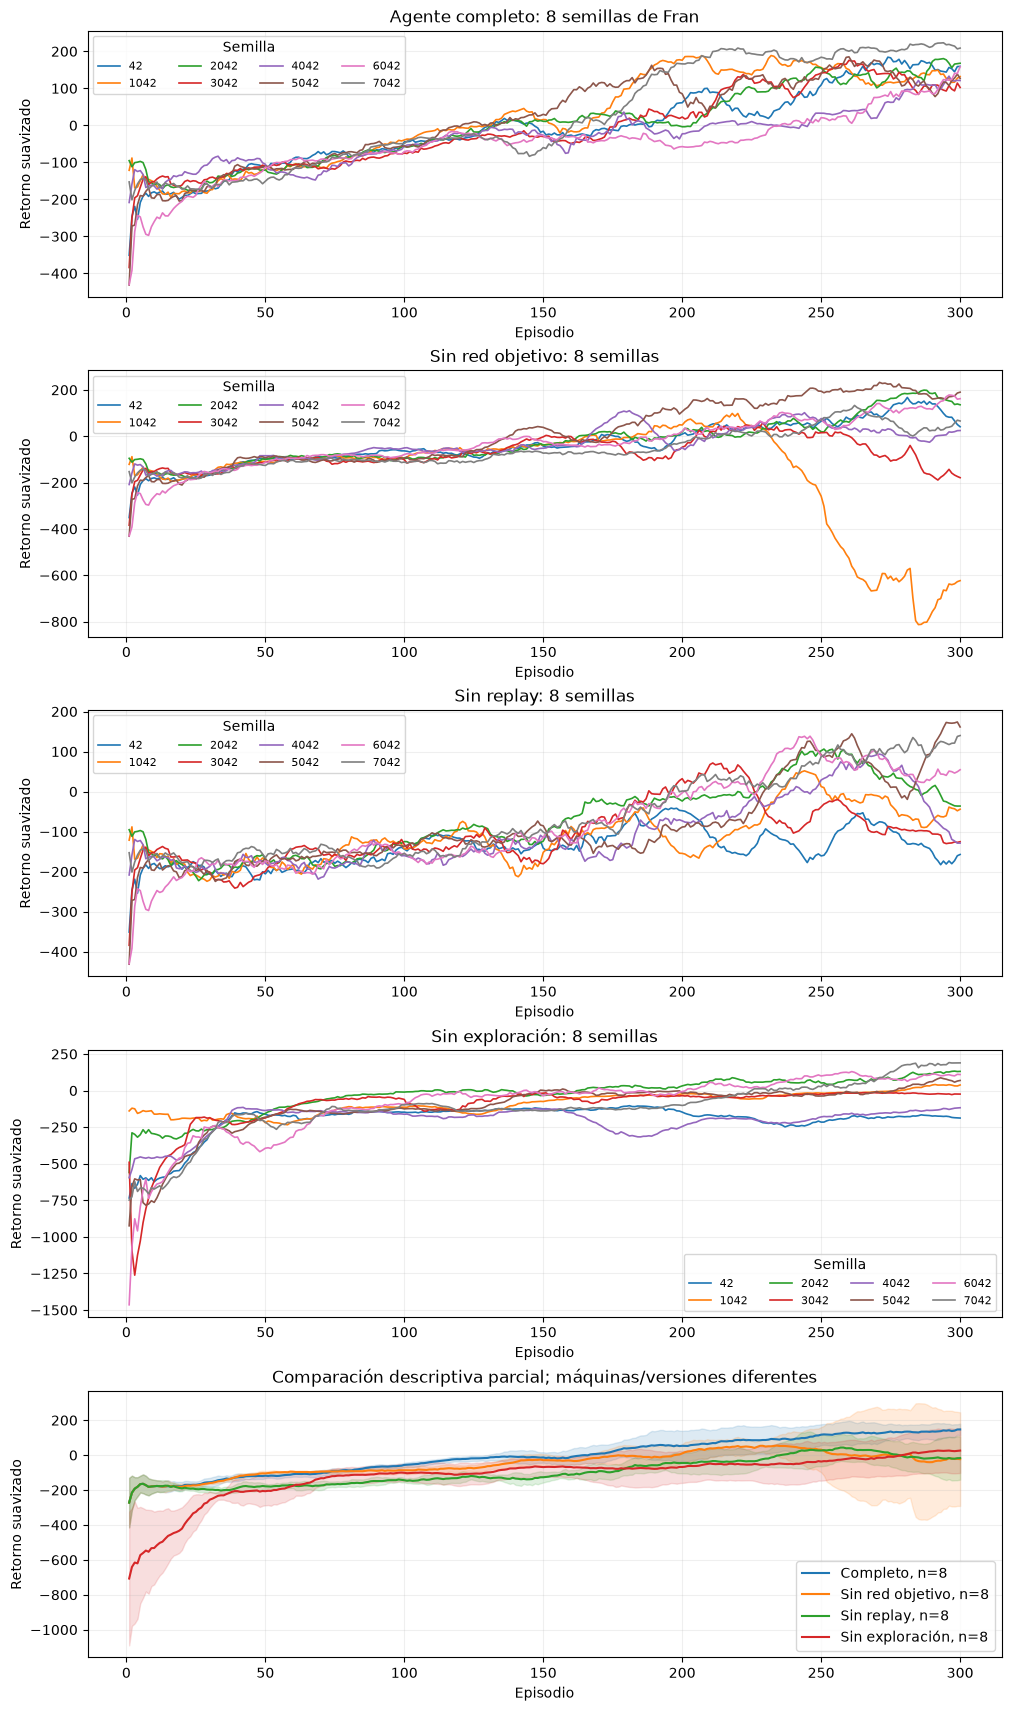

In [10]:
curvas = {(variante(r['config']), r['config']['training_seed']): media_movil(
    [float(f['return']) for f in r['training']], ventana=20) for r in RUNS}
comunes = sorted({s for v,s in curvas if v == 'full'} & {s for v,s in curvas if v == 'no_target'})
fig, axes = plt.subplots(5, 1, figsize=(10, 17), constrained_layout=True)
episodios = np.arange(1, 301)
for ax, v, titulo in [(axes[0], 'full', 'Agente completo: 8 semillas de Fran'), (axes[1], 'no_target', 'Sin red objetivo: 8 semillas'), (axes[2], 'no_replay', 'Sin replay: 8 semillas'), (axes[3], 'no_exploration', 'Sin exploración: 8 semillas')]:
    for (condicion, semilla), valores in sorted(curvas.items()):
        if condicion == v:
            ax.plot(episodios, valores, label=str(semilla), linewidth=1.2)
    ax.set(title=titulo, xlabel='Episodio', ylabel='Retorno suavizado')
    ax.legend(title='Semilla', ncol=4, fontsize=8)
    ax.grid(alpha=.2)
for v, etiqueta in [('full', 'Completo'), ('no_target', 'Sin red objetivo'), ('no_replay', 'Sin replay'), ('no_exploration', 'Sin exploración')]:
    matriz = np.stack([curvas[v,s] for s in comunes])
    media, sd = matriz.mean(axis=0), matriz.std(axis=0, ddof=1)
    linea, = axes[4].plot(episodios, media, label=f'{etiqueta}, n={len(comunes)}')
    axes[4].fill_between(episodios, media-sd, media+sd, color=linea.get_color(), alpha=.15)
axes[4].set(title='Comparación descriptiva parcial; máquinas/versiones diferentes', xlabel='Episodio', ylabel='Retorno suavizado')
axes[4].legend()
axes[4].grid(alpha=.2)
plt.show()

### Evaluación y baseline aleatorio
Se presentan métricas por política, sin tests inferenciales. Se recarga el checkpoint completo de semilla 42 y se comprueba su evaluación en las mismas semillas. El baseline aleatorio también se evalúa en esos resets. El checkpoint se fijó por su semilla, sin elegir el mejor resultado.

Condición,Semilla,Retorno medio,Éxitos R≥200,Pasos de entrenamiento
full,42,174.90,68/200,158659
full,1042,183.24,85/200,153312
full,2042,80.58,63/200,159763
full,3042,69.52,7/200,155482
full,4042,60.50,69/200,165167
full,5042,121.94,72/200,143546
full,6042,203.15,143/200,155138
full,7042,208.70,140/200,126703
no_exploration,42,-168.71,0/200,32968
no_exploration,1042,62.62,15/200,228980


Reevaluación coincide con el entorno original: False
Los resultados originales se conservan; una reevaluación en otra plataforma no los reemplaza.

Completo, semilla 42, reevaluación de desarrollo - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 31.5%
Recompensa promedio: 168.86
Recompensa mediana:  180.97
Desviación estándar: 81.11
Total de éxitos: 63 / 200

Baseline aleatorio, desarrollo - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 0.0%
Recompensa promedio: -183.17
Recompensa mediana:  -149.80
Desviación estándar: 111.96
Total de éxitos: 0 / 200


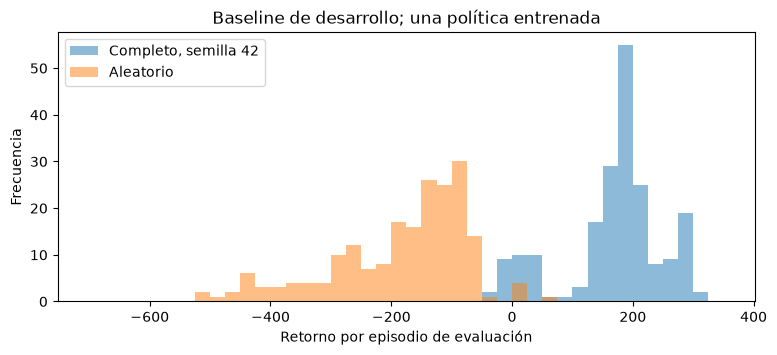

In [11]:
filas = []
for r in sorted(RUNS, key=lambda r: (variante(r['config']), r['config']['training_seed'])):
    c, s = r['config'], r['summary']
    filas.append(f"<tr><td>{html.escape(variante(c))}</td><td>{c['training_seed']}</td><td>{s['mean_return']:.2f}</td><td>{s['successes']}/{s['evaluated']}</td><td>{s['total_steps']}</td></tr>")
display(HTML('<table><tr><th>Condición</th><th>Semilla</th><th>Retorno medio</th><th>Éxitos R≥200</th><th>Pasos de entrenamiento</th></tr>' + ''.join(filas) + '</table>'))
entorno = gym.make('LunarLander-v3', continuous=False, enable_wind=False)
try:
    politica = AgenteDQN(entorno.observation_space, entorno.action_space, semilla=42)
    politica.red_q.load_state_dict(torch.load(io.BytesIO(PESOS), map_location='cpu', weights_only=True))
    politica.red_q.eval()
    originales = {k: v.clone() for k,v in politica.red_q.state_dict().items()}
    evaluacion = evaluar_agente(politica, entorno, num_episodios=200, semilla=10000)
    coincide = np.allclose(evaluacion['recompensas_totales'], [float(r['return']) for r in referencia['evaluation']], atol=1e-4, rtol=1e-6)
    print('Reevaluación coincide con el entorno original:', coincide)
    print('Los resultados originales se conservan; una reevaluación en otra plataforma no los reemplaza.')
    assert politica.env_steps == politica.optimizer_updates == 0
    assert all(torch.equal(v, originales[k]) for k,v in politica.red_q.state_dict().items())
    azar = AgenteAleatorio(entorno.action_space, semilla=42)
    evaluacion_azar = evaluar_agente(azar, entorno, num_episodios=200, semilla=10000)
finally:
    entorno.close()
imprimir_resultados_evaluacion(evaluacion, 'Completo, semilla 42, reevaluación de desarrollo')
imprimir_resultados_evaluacion(evaluacion_azar, 'Baseline aleatorio, desarrollo')
fig, ax = plt.subplots(figsize=(9, 3.5))
for resultado, etiqueta in [(evaluacion, 'Completo, semilla 42'), (evaluacion_azar, 'Aleatorio')]:
    ax.hist(resultado['recompensas_totales'], bins=np.linspace(-700, 350, 43), alpha=.5, label=etiqueta)
ax.set(xlabel='Retorno por episodio de evaluación', ylabel='Frecuencia', title='Baseline de desarrollo; una política entrenada')
ax.legend()
plt.show()

## 9. Visualización de la política aprendida

Se corren 10 episodios sin exploración sobre semillas sorteadas, sin elegir
los que salieron bien, y se arma un GIF con los diez en una grilla. Cada cuadro
muestra al terminar la recompensa del episodio, en verde si llegó al umbral de éxito
y en rojo si no.

### GIF de la integración
Se genera el GIF de diez episodios del checkpoint completo de Fran de semilla 42. Las semillas de rollout se sortean de 20000–29999 con generador 42 y se muestran todos los resultados. Son semillas de visualización, no la evaluación reservada. `RUN_GIF=False` omite el renderizado por defecto; activarlo para regenerarlo.

  semilla 20892:  600 pasos, recompensa   222.0


  semilla 27739:  597 pasos, recompensa   204.5


  semilla 26545:  985 pasos, recompensa   124.6


  semilla 24388:  268 pasos, recompensa   274.8


  semilla 24330: 1000 pasos, recompensa    32.8


  semilla 28585:  963 pasos, recompensa   171.5


  semilla 20859:  905 pasos, recompensa   115.6


  semilla 26973:  371 pasos, recompensa   283.1


  semilla 22014:  756 pasos, recompensa   175.4


  semilla 20941:  322 pasos, recompensa   229.3



5/10 episodios exitosos, recompensa media 183.4 → aterrizaje_dqn.gif


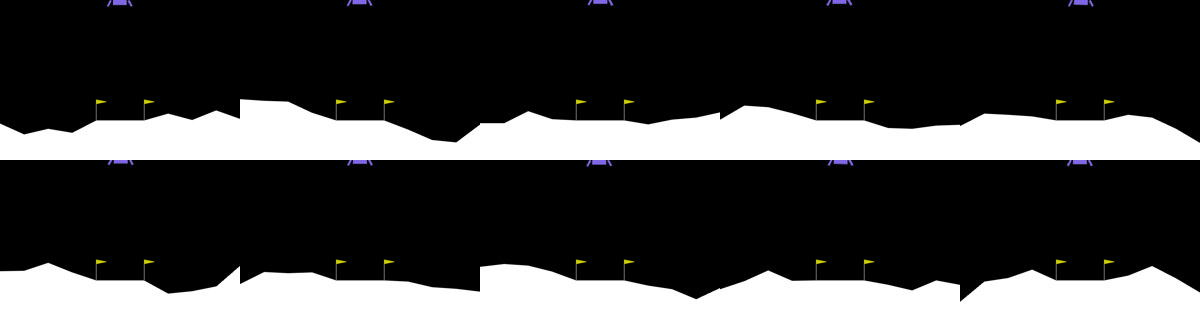

In [12]:
RUN_GIF = False
agente_dqn = politica
from PIL import Image, ImageDraw
from IPython.display import Image as MostrarImagen, display

ANCHO_CUADRO, ALTO_CUADRO = 240, 160

def _correr_episodio_render(agente, env, semilla, salto):
    """Corre un episodio renderizando y devuelve (cuadros, recompensa, pasos)."""
    estado, _ = env.reset(seed=semilla)
    cuadros, recompensa_total, paso = [], 0.0, 0
    while True:
        if paso % salto == 0:
            cuadros.append(Image.fromarray(env.render()).resize((ANCHO_CUADRO, ALTO_CUADRO)))
        estado, recompensa, terminado, truncado, _ = env.step(agente.elegir_accion(estado, explorar=False))
        recompensa_total += recompensa
        paso += 1
        if terminado or truncado:
            cuadros.append(Image.fromarray(env.render()).resize((ANCHO_CUADRO, ALTO_CUADRO)))
            break
    return cuadros, recompensa_total, paso


def _rotular(cuadro, recompensa, umbral):
    """Escribe la recompensa final sobre el cuadro: verde si es éxito, rojo si no."""
    cuadro = cuadro.copy()
    color = (40, 170, 70) if recompensa >= umbral else (210, 50, 50)
    ImageDraw.Draw(cuadro).text((6, 4), f"R = {recompensa:.0f}", fill=color)
    return cuadro


def grabar_episodios(agente, ruta_gif='aterrizaje_dqn.gif', semillas=range(10_000, 10_010),
                     columnas=5, salto=3, umbral=UMBRAL_EXITO):
    """Corre un episodio sin exploración por semilla y guarda un GIF con todos en
    una grilla. Los episodios que terminan antes quedan quietos en su último cuadro,
    rotulado con la recompensa obtenida."""
    env = gym.make('LunarLander-v3', render_mode='rgb_array')
    episodios = []
    try:
        for semilla in semillas:
            cuadros, recompensa_total, pasos = _correr_episodio_render(agente, env, semilla, salto)
            print(f"  semilla {semilla}: {pasos:4d} pasos, recompensa {recompensa_total:7.1f}")
            cuadros[-1] = _rotular(cuadros[-1], recompensa_total, umbral)
            episodios.append((cuadros, recompensa_total))
    finally:
        env.close()

    filas = -(-len(episodios) // columnas)
    largo = max(len(cuadros) for cuadros, _ in episodios)
    fotogramas = []
    for t in range(largo):
        lienzo = Image.new('RGB', (columnas * ANCHO_CUADRO, filas * ALTO_CUADRO), 'white')
        for i, (cuadros, _) in enumerate(episodios):
            lienzo.paste(cuadros[min(t, len(cuadros) - 1)],
                         ((i % columnas) * ANCHO_CUADRO, (i // columnas) * ALTO_CUADRO))
        fotogramas.append(lienzo)
    fotogramas[0].save(ruta_gif, save_all=True, append_images=fotogramas[1:], duration=50, loop=0)

    recompensas = np.array([r for _, r in episodios])
    print(f"\n{(recompensas >= umbral).sum()}/{len(recompensas)} episodios exitosos, "
          f"recompensa media {recompensas.mean():.1f} → {ruta_gif}")
    return ruta_gif, recompensas


if RUN_GIF:
    # Semillas sorteadas, no elegidas: el GIF muestra los diez episodios salgan como salgan.
    semillas_gif = np.random.default_rng(SEMILLA).integers(20_000, 30_000, size=10).tolist()
    ruta, _ = grabar_episodios(agente_dqn, semillas=semillas_gif)
    display(MostrarImagen(filename=ruta))
else:
    print("GIF opcional omitido; activar RUN_GIF para generarlo.")


## 10. Qué aprendió la política

Analicen la política aprendida utilizando cortes con valores fijos en algunas
dimensiones para validar lo aprendido.


### TODO 2 resuelto: cortes de política
Se incorpora el código de Agustín y se regenera el corte representativo con los pesos incorporados. Los estados sintéticos pueden ser inalcanzables; Q no es probabilidad. Los puntos proyectados desde rollouts no fijan las otras seis dimensiones al valor del corte. Las figuras de ocho semillas y la comparación con sin exploración se incorporan como salidas originales con su procedencia.

Escalas comprobadas en `LunarLander.step` de Gymnasium 1.4.0 (también aplicables a las figuras históricas incorporadas): con W=600, H=400, SCALE=30 y FPS=50, las observaciones son x=(pos.x−10)/10, y=(pos.y−helipad_y−LEG_DOWN/30)/(20/3), vx=vel.x/5, vy=vel.y·(2/15), θ=angle en radianes y ω=angularVelocity·0.4. Son coordenadas de observación; no se atribuyen metros ni m/s a los ejes. No se añadió normalización propia ni se transformaron los valores de los cortes. Las figuras históricas conservan sus salidas originales y su leyenda; sus símbolos se interpretan con estas escalas. Fuente: https://github.com/Farama-Foundation/Gymnasium/blob/v1.4.0/gymnasium/envs/box2d/lunar_lander.py .

In [13]:
import argparse
import json
from pathlib import Path
import gymnasium as gym
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import torch
from gymnasium.envs.box2d.lunar_lander import heuristic
from matplotlib.colors import BoundaryNorm, ListedColormap
from torch import nn
ACCIONES = ['Nada', 'Motor izq. (gira +)', 'Motor principal', 'Motor der. (gira −)']
COLORES = ListedColormap(['#bbbbbb', '#e69f00', '#009e73', '#0072b2'])
NORMA = BoundaryNorm(np.arange(-0.5, 4.5, 1), 4)
NOMBRES = {'full': 'Completo', 'no_exploration': 'Sin exploración', 'no_replay': 'Sin replay', 'no_target': 'Sin red objetivo'}
ESTADO_FIJO = np.array([0, 0.8, 0, -0.3, 0, 0, 0, 0], dtype=np.float32)
CORTES = [(0, 2, (-1, 1), (-1.5, 1.5), 'x (obs. escalada)', 'vx (obs. escalada)'), (4, 5, (-0.7, 0.7), (-1.5, 1.5), 'θ (rad)', 'ω (obs. escalada)'), (1, 3, (0.1, 1.5), (-2, 1), 'y (obs. escalada)', 'vy (obs. escalada)')]
SEMILLA_EVAL, EPISODIOS = (10000, 20)
RESOLUCION = 101

def variante(config):
    """Nombre de la variante a partir de los interruptores guardados en config.json."""
    if not config.get('use_target', True):
        return 'no_target'
    if not config.get('use_replay', True):
        return 'no_replay'
    if not config.get('use_exploration', True):
        return 'no_exploration'
    return 'full'

def cargar_red(carpeta):
    """Reconstruye la red Q (8 -> 64 -> 64 -> 4) y carga los pesos finales."""
    config = json.loads((carpeta / 'config.json').read_text())
    h1, h2 = config['hidden_dims']
    red = nn.Sequential(nn.Linear(8, h1), nn.ReLU(), nn.Linear(h1, h2), nn.ReLU(), nn.Linear(h2, 4))
    red.load_state_dict(torch.load(carpeta / 'online_weights.pt', map_location='cpu', weights_only=True))
    red.eval()
    return (red, config)

def q_de(red, estados):
    with torch.no_grad():
        return red(torch.as_tensor(np.asarray(estados, dtype=np.float32))).numpy()

def corte(red, ix, iy, rx, ry):
    """Evalúa la red en una grilla que varía dos dimensiones y deja las otras seis fijas."""
    x, y = (np.linspace(*rx, RESOLUCION), np.linspace(*ry, RESOLUCION))
    xx, yy = np.meshgrid(x, y)
    estados = np.tile(ESTADO_FIJO, (xx.size, 1))
    estados[:, ix], estados[:, iy] = (xx.ravel(), yy.ravel())
    q = q_de(red, estados).reshape(RESOLUCION, RESOLUCION, 4)
    return (x, y, q, estados)

def jugar(red, episodios=EPISODIOS):
    """Episodios greedy reales. Devuelve estados, acciones y cómo terminó cada episodio."""
    env = gym.make('LunarLander-v3', continuous=False, enable_wind=False)
    estados, acciones, finales = ([], [], [])
    try:
        for i in range(episodios):
            s, _ = env.reset(seed=SEMILLA_EVAL + i)
            total, pasos = (0.0, 0)
            while True:
                a = int(q_de(red, s[None])[0].argmax())
                estados.append(s)
                acciones.append(a)
                s, r, terminado, truncado, _ = env.step(a)
                total += r
                pasos += 1
                if terminado or truncado:
                    break
            fin = 'posado' if terminado and r == 100 else 'choque' if terminado else 'flotando'
            finales.append(dict(semilla=SEMILLA_EVAL + i, recompensa=total, pasos=pasos, fin=fin))
    finally:
        env.close()
    return (np.array(estados), np.array(acciones), finales)

def acuerdo_heuristica(estados, acciones):
    """Fracción de estados donde la acción del DQN coincide con `heuristic` de Gymnasium."""
    env = gym.make('LunarLander-v3').unwrapped
    esperadas = np.array([heuristic(env, s) for s in estados])
    env.close()
    return (float((esperadas == acciones).mean()), esperadas)

def dibujar_corte(ax_a, ax_q, red, spec, visitados=None, titulo=''):
    ix, iy, rx, ry, lx, ly = spec
    x, y, q, _ = corte(red, ix, iy, rx, ry)
    ax_a.pcolormesh(x, y, q.argmax(axis=2), shading='auto', cmap=COLORES, norm=NORMA)
    if visitados is not None:
        ax_a.scatter(visitados[:, ix], visitados[:, iy], s=1, c='black', alpha=0.15)
        ax_a.set_xlim(rx)
        ax_a.set_ylim(ry)
    ax_a.set(xlabel=lx, ylabel=ly, title=titulo)
    if ax_q is not None:
        im = ax_q.pcolormesh(x, y, q.max(axis=2), shading='auto', cmap='viridis')
        plt.colorbar(im, ax=ax_q, label='max Q')
        ax_q.set(xlabel=lx, ylabel=ly)

def leyenda_acciones(fig):
    from matplotlib.patches import Patch
    fig.legend(handles=[Patch(color=COLORES(i), label=n) for i, n in enumerate(ACCIONES)], loc='lower center', ncol=4, fontsize=9, frameon=False)

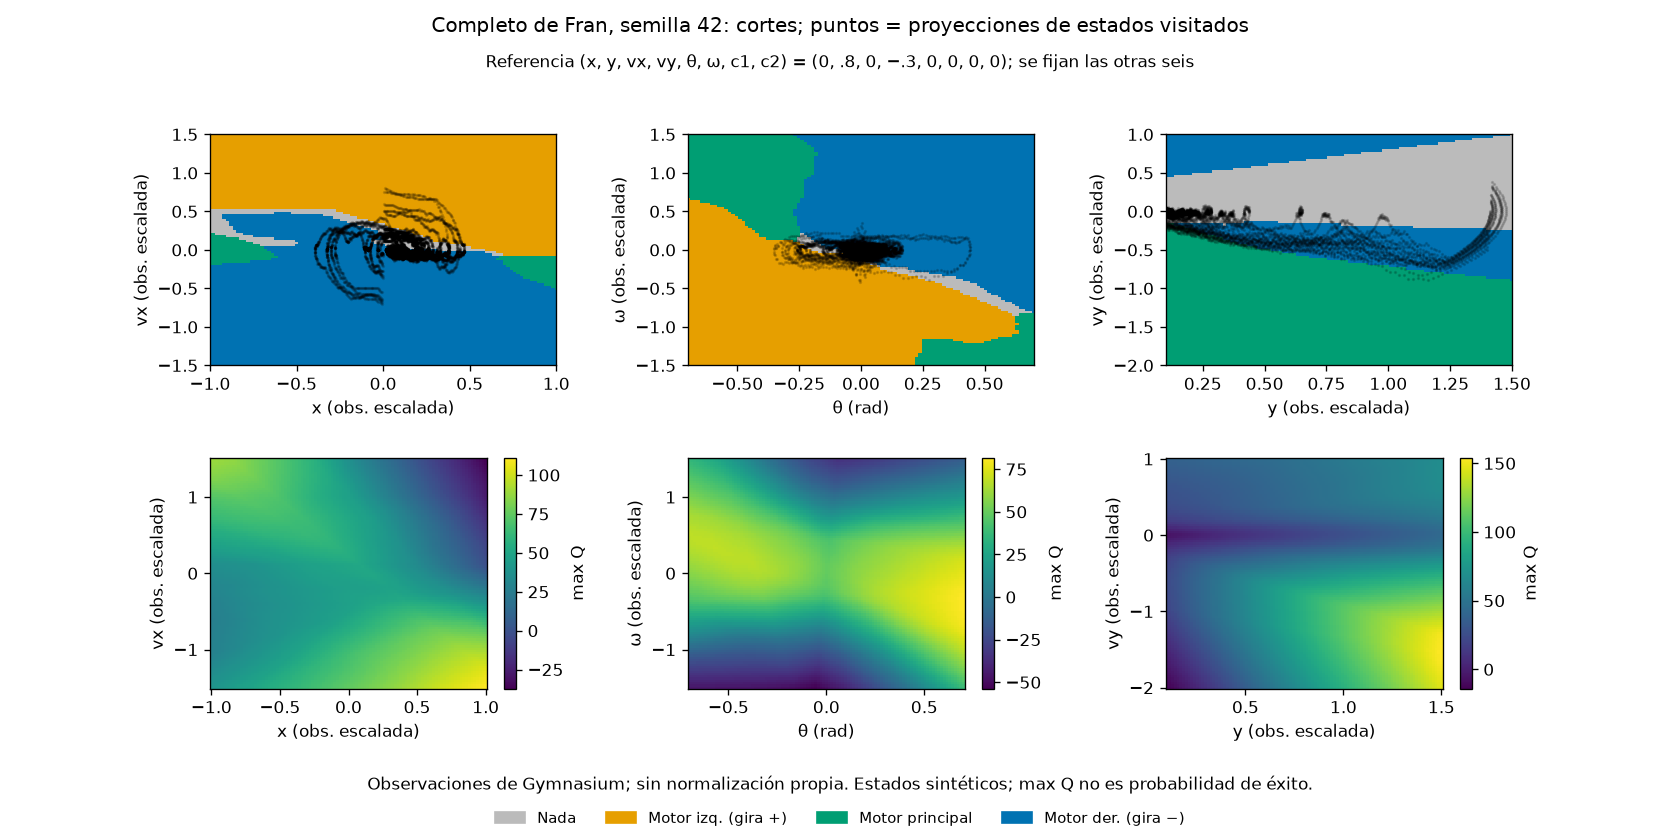

Estado fijo de referencia: [0.0, 0.800000011920929, 0.0, -0.30000001192092896, 0.0, 0.0, 0.0, 0.0]
Rollouts de desarrollo: 10000 a 10019


In [14]:
visitados, acciones, episodios_policy = jugar(politica.red_q, episodios=20)
fig, ejes = plt.subplots(2, 3, figsize=(14, 7), constrained_layout=False)
for columna, spec in enumerate(CORTES):
    dibujar_corte(ejes[0,columna], ejes[1,columna], politica.red_q, spec, visitados)
fig.suptitle('Completo de Fran, semilla 42: cortes; puntos = proyecciones de estados visitados')
leyenda_acciones(fig)
fig.subplots_adjust(bottom=.18, top=.84, hspace=.40, wspace=.38)
fig.text(.5, .92, 'Referencia (x, y, vx, vy, θ, ω, c1, c2) = (0, .8, 0, −.3, 0, 0, 0, 0); se fijan las otras seis', ha='center', fontsize=10)
fig.text(.5, .06, 'Observaciones de Gymnasium; sin normalización propia. Estados sintéticos; max Q no es probabilidad de éxito.', ha='center', fontsize=10)
plt.show()
print('Estado fijo de referencia:', ESTADO_FIJO.tolist())
print('Rollouts de desarrollo:', SEMILLA_EVAL, 'a', SEMILLA_EVAL + 19)

Salida original de Agustín: cortes_8_semillas_angulo.png


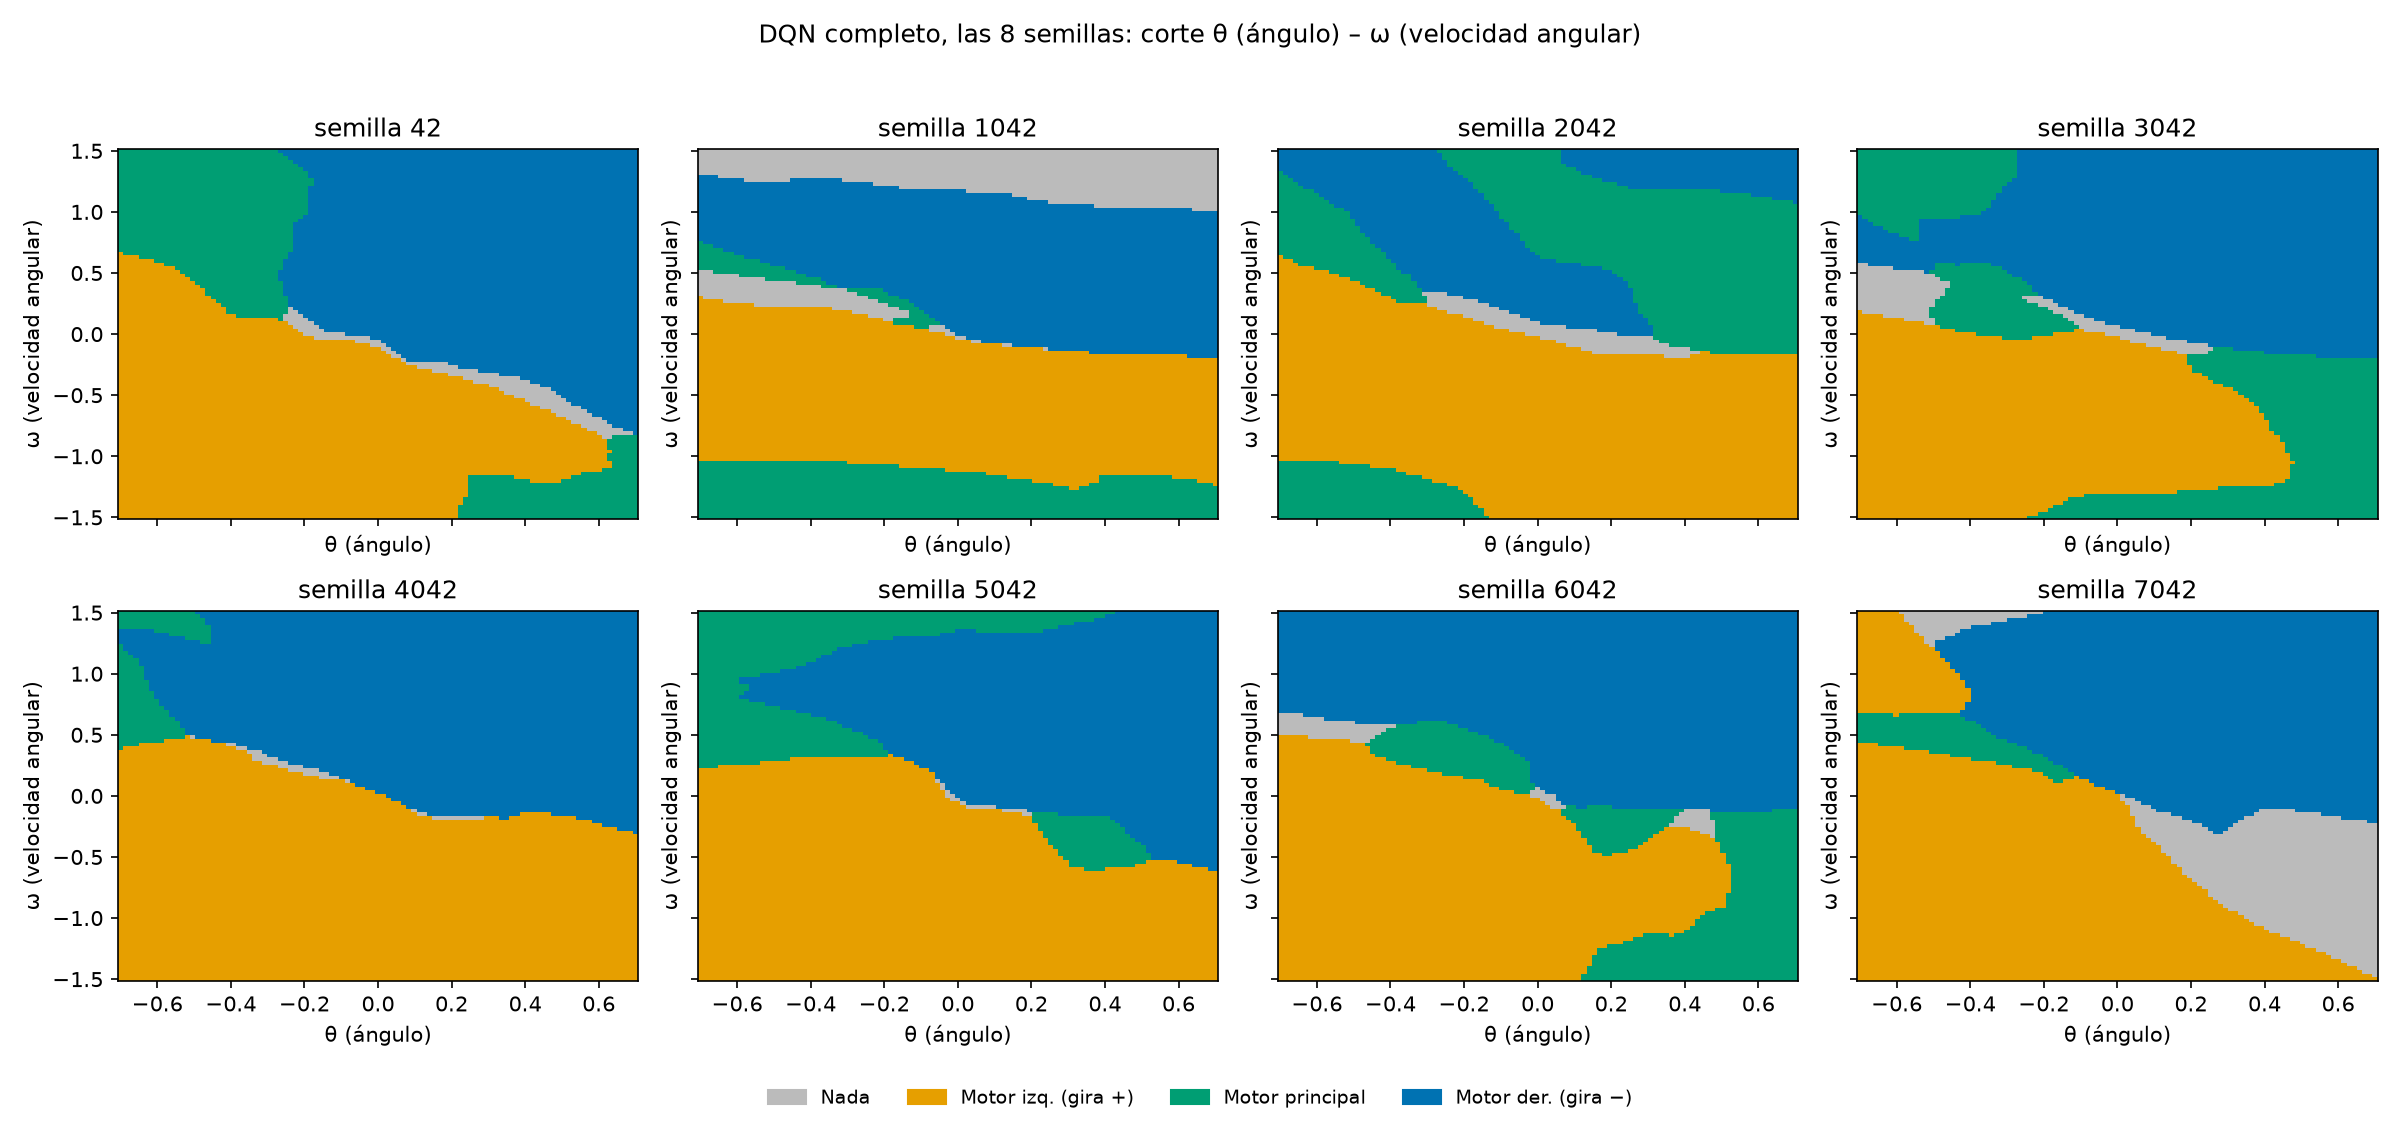

Salida original de Agustín: cortes_completo_vs_sin_exploracion.png


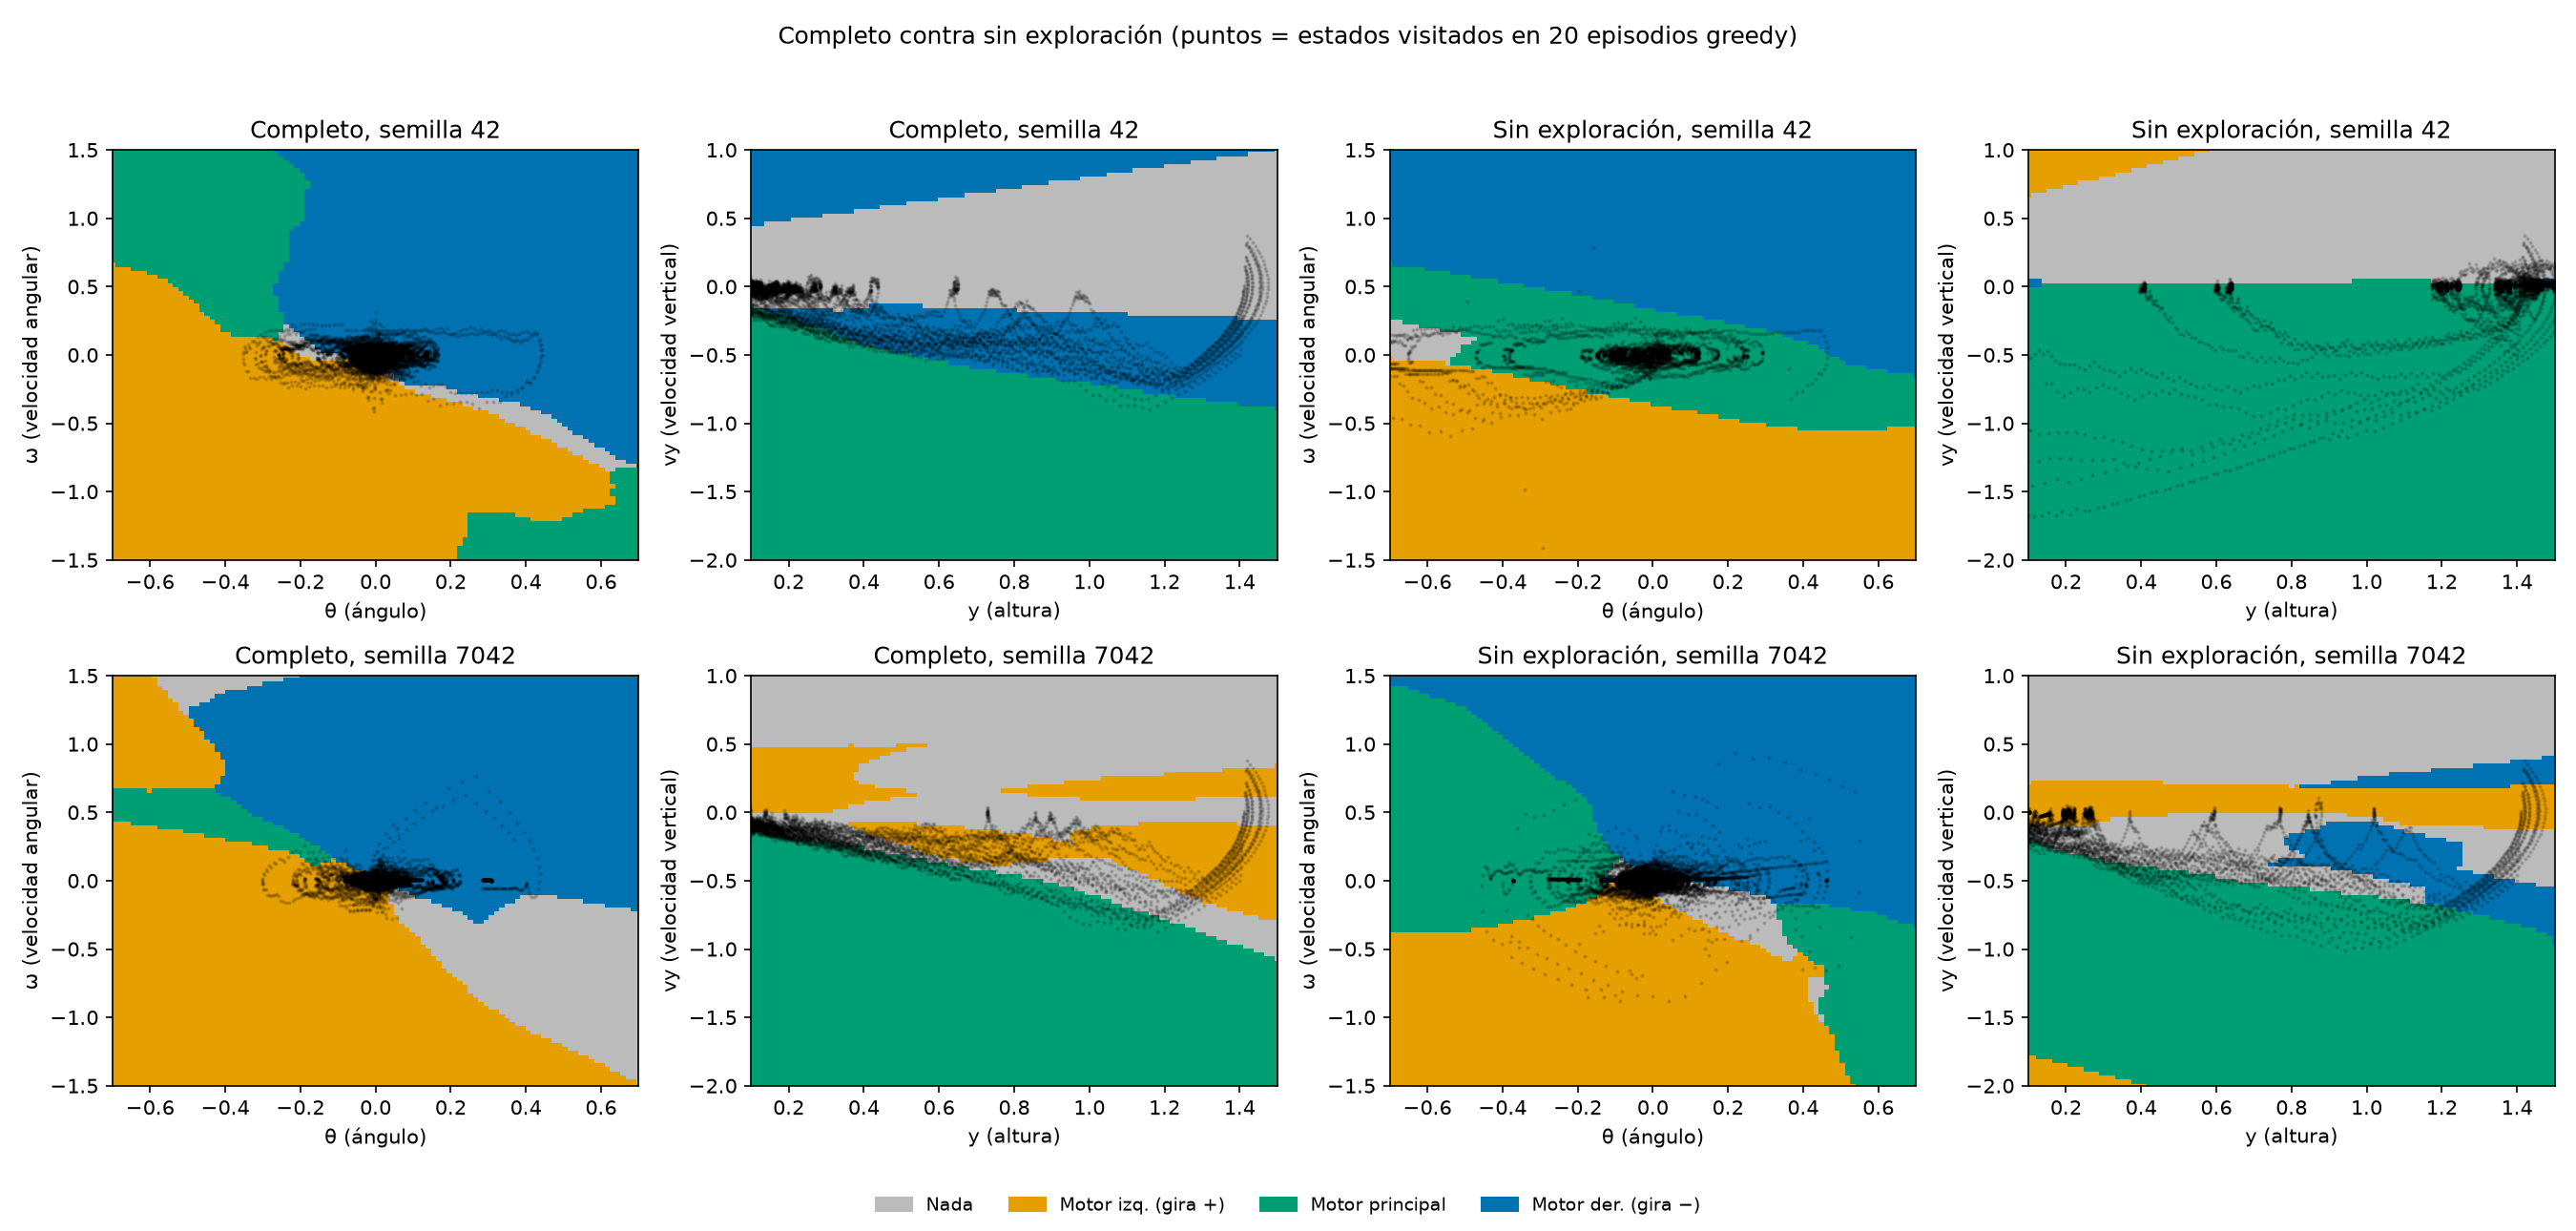

In [15]:
FIGURAS_AGUSTIN = {'cortes_8_semillas_angulo.png': '...', 'cortes_completo_vs_sin_exploracion.png': '...'}
for nombre, datos in FIGURAS_AGUSTIN.items():
    print('Salida original de Agustín:', nombre)
    display(MostrarImagen(data=base64.b64decode(datos)))

## 11. Estudio de ablación

Las secciones anteriores muestran que el DQN completo funciona, pero no *cuánto*
aporta cada una de sus piezas. Una **ablación** responde eso: se reentrena el
agente desde cero desactivando (o degradando) un componente por vez y se mide
cuánto cae el desempeño respecto de la configuración completa.

Comparen el DQN completo contra, como mínimo, tres variantes correspondientes a
quitar características de DQN. Cada configuración se entrena con varias semillas y
se evalúa sobre las mismas semillas de evaluación, sin exploración. Reporten para
cada variante la recompensa de evaluación por semilla y comparen contra el DQN
completo con un test estadístico adecuado.


### TODO 3 resuelto: ablaciones, cobertura y tests
32 políticas, ocho por condición; unidad experimental: media de los 200 retornos de cada política, reconstruida desde registros individuales. Los episodios no son réplicas de entrenamiento.

Registro R01 (revisión posterior): MW bilateral exacto con Holm fue la propuesta original de Agustín; Wilcoxon era sensibilidad. Ahora se prioriza la interpretación por bloques de semilla con Wilcoxon, por el diseño compartido, no por el valor p. MW se conserva como complementario condicionado; no se reescribe el protocolo previo.

MW: H0 de igualdad de distribuciones de medias por política frente a alternativa bilateral; requiere muestras independientes y el cálculo exacto usado requiere ausencia de empates. No es exclusivamente un test de medias. La independencia entre variantes no está justificada. Wilcoxon: H0 de diferencias simétricas alrededor de cero; bajo un modelo de desplazamiento simétrico, centro cero frente a distinto de cero. Requiere bloques independientes y diferencias de distribución común y simétrica. Ocho pares no verifican simetría: la inferencia permanece condicionada. Se comprueban ceros y empates de magnitud antes del cálculo exacto. Holm se aplica por separado a las tres comparaciones de cada método, sin requerir independencia entre contrastes; no elegir el menor p entre métodos.

Se comparten semillas de inicialización de generadores y resets; replay y exploración alteran el consumo posterior. Los prefijos de filas de entrenamiento completo/sin replay coinciden en 9–11 episodios por semilla. Eso es evidencia de aleatoriedad compartida, no de trayectorias completas idénticas. Las plataformas/versiones difieren y el número de semilla no garantiza un bloqueo causal perfecto; trayectorias diferentes tampoco prueban independencia. Los escenarios de evaluación 10000–10199 son comunes y de desarrollo: la inferencia entre bloques se condiciona a ese conjunto fijo. No elimina confusión de plataforma ni estima generalización a escenarios nuevos.

No se agrega test de signos ni una prueba de simetría de baja potencia para decidir el método. Se conserva la limitación de simetría sin darla por demostrada. Los efectos cruzados (HL y U/64) son descriptivos, no efectos emparejados; se muestran además dispersión y rango de las diferencias. No rechazar no demuestra equivalencia. El informe requiere conciliación por los autores según H03; esta revisión técnica no la sustituye.

In [ ]:
planeadas = {42,1042,2042,3042,4042,5042,6042,7042}
for v in ['full', 'no_target', 'no_replay', 'no_exploration']:
    disponibles = {s for condicion,s in vistos if condicion == v}
    print(f'{v}: {len(disponibles)}/8; faltan {sorted(planeadas-disponibles)}')
assert len(vistos) == 32
print('Evaluación reservada: no realizada.')

full: 8/8; faltan []
no_target: 8/8; faltan []
no_replay: 8/8; faltan []
no_exploration: 8/8; faltan []
Evaluación reservada: no realizada.


In [ ]:
from scipy import stats
def holm(pvalores, m):
    """Holm-Bonferroni: p ajustados para m comparaciones planeadas.

    Si falta alguna comparación (m > len(pvalores)) los p devueltos no son finales.
    """
    orden = sorted(range(len(pvalores)), key=lambda i: pvalores[i])
    ajustados = [None] * len(pvalores)
    maximo = 0.0
    for rango, i in enumerate(orden):
        maximo = max(maximo, min(1.0, (m - rango) * pvalores[i]))
        ajustados[i] = maximo
    return ajustados

def comparar_una(completo, ablacion):
    """Compara dos diccionarios {semilla: media} y devuelve estadísticos y efectos."""
    if set(completo) != set(ablacion):
        raise ValueError('Se requieren los mismos bloques por semilla; no descartar pares.')
    semillas = sorted(completo)
    c = np.array([completo[s] for s in semillas], dtype=float)
    a = np.array([ablacion[s] for s in semillas], dtype=float)
    if not len(c) or not np.isfinite(np.r_[c, a]).all():
        raise ValueError('Medias vacías o no finitas')
    empates = len(c) + len(a) - len(np.unique(np.r_[c, a]))
    if empates:
        raise ValueError('MW exacto sin corrección de empates no es válido aquí')
    u = stats.mannwhitneyu(c, a, alternative='two-sided', method='exact')
    fila = dict(n_completo=len(c), n_ablacion=len(a), empates_mw=int(empates), media_completo=float(c.mean()), media_ablacion=float(a.mean()), diferencia_media=float(c.mean() - a.mean()), diferencia_mediana=float(np.median(c) - np.median(a)), hodges_lehmann=float(np.median(np.subtract.outer(c, a))), U=float(u.statistic), p_mann_whitney=float(u.pvalue), prob_superioridad=float(u.statistic / (len(c) * len(a))))
    comunes = sorted(set(completo) & set(ablacion))
    if len(comunes) >= 5:
        dif = np.array([completo[s] - ablacion[s] for s in comunes])
        ceros = int((dif == 0).sum())
        empates_abs = len(dif) - len(np.unique(np.abs(dif)))
        if ceros or empates_abs:
            raise ValueError('Wilcoxon exacto requiere revisar ceros/empates de magnitud')
        w = stats.wilcoxon(dif, alternative='two-sided', method='exact')
        fila.update(n_pares=len(comunes), W=float(w.statistic), p_wilcoxon=float(w.pvalue), completo_gana=int((dif > 0).sum()), semillas=comunes, diferencias=dif.tolist(), ceros=ceros, empates_abs=int(empates_abs), sd_diferencias=float(dif.std(ddof=1)), mediana_diferencias=float(np.median(dif)), minimo_diferencias=float(dif.min()), maximo_diferencias=float(dif.max()))
    return fila

def ajustar_familias(filas, completas=True):
    """Dos familias de tres; Holm no requiere independencia entre contrastes.

    p_holm conserva el nombre histórico de MW para compatibilidad.
    No se produce una etiqueta genérica de significación.
    """
    pm = holm([f['p_mann_whitney'] for f in filas], 3)
    paired = all(('p_wilcoxon' in f for f in filas))
    pw = holm([f['p_wilcoxon'] for f in filas], 3) if paired else [None] * len(filas)
    final = completas and len(filas) == 3 and paired
    for f, m, w in zip(filas, pm, pw):
        f.update(p_holm=m, p_wilcoxon_holm=w, significativo_mw_condicionado=m < 0.05 if final else None, significativo_wilcoxon_condicionado=w < 0.05 if final else None)

In [ ]:
medias = {}
for r in RUNS:
    v, seed = variante(r['config']), r['config']['training_seed']
    assert seed not in medias.setdefault(v, {})
    assert [int(x['reset_seed']) for x in r['evaluation']] == list(range(10000,10200))
    retornos = np.array([float(x['return']) for x in r['evaluation']])
    assert np.isfinite(retornos).all()
    medias[v][seed] = float(retornos.mean())
    assert abs(medias[v][seed] - r['summary']['mean_return']) < 1e-10
assert all(set(m) == planeadas for m in medias.values())
tabla_medias = '<table><tr><th>Semilla</th><th>Completo</th><th>Sin objetivo</th><th>Sin replay</th><th>Sin exploración</th></tr>'
for seed in sorted(planeadas):
    tabla_medias += '<tr><td>'+str(seed)+'</td>'+''.join(f'<td>{medias[v][seed]:.6f}</td>' for v in ['full','no_target','no_replay','no_exploration'])+'</tr>'
display(HTML(tabla_medias+'</table>'))
tests = [dict(variante=v, **comparar_una(medias['full'], medias[v])) for v in ['no_target','no_replay','no_exploration']]
ajustar_familias(tests)
columnas = ['variante','diferencia_media','sd_diferencias','mediana_diferencias','minimo_diferencias','maximo_diferencias','U','p_mann_whitney','p_holm','W','p_wilcoxon','p_wilcoxon_holm','ceros','empates_mw','empates_abs']
etiquetas = ['Ablación','Δ media','DE diferencias','Mediana diferencias','Mín. diferencias','Máx. diferencias','U','p MW complementario','p MW/H complementario','W','p Wilcoxon','p Wilcoxon/H','Ceros','Empates MW','Empates |d|']
tabla = '<table><tr>'+''.join('<th>'+x+'</th>' for x in etiquetas)+'</tr>'
for r in tests:
    tabla += '<tr>'+''.join('<td>'+(f'{r[k]:.6f}' if isinstance(r[k],float) else str(r[k]))+'</td>' for k in columnas)+'</tr>'
display(HTML(tabla+'</table>'))
assert len(tests) == 3 and all(r['n_completo'] == r['n_ablacion'] == r['n_pares'] == 8 for r in tests)
print('Inferencia condicionada a supuestos; únicamente sin replay rechaza con Wilcoxon/Holm a 0.05. No rechazo no implica equivalencia.')


<IPython.core.display.HTML object>
<IPython.core.display.HTML object>
Inferencia condicionada a supuestos; únicamente sin replay rechaza con Wilcoxon/Holm a 0.05. No rechazo no implica equivalencia.


## Evidencia incorporada H01: antecedentes y reevaluación auxiliar

Este bloque es independiente de `RUNS`, `AgenteDQN` y `politica`: **no reemplaza ni duplica las 32 corridas finales**. Los antecedentes tienen implementaciones y presupuestos distintos. Ejecutarlo solo decodifica evidencia y recalcula tablas; todo entrenamiento histórico queda desactivado. Se conservan los bytes originales de los CSV/JSON y el código fuente histórico, con SHA-256 y procedencia por archivo/celda. No necesita red, Git ni rutas externas al ejecutarse.

**Calibración, tabla II:** ocho políticas del 27 y 29/10, 300 episodios (máximo 1000 pasos), 200 evaluaciones greedy desde 10000. A0 histórico usa 64/64 y 0.001; A1 128/128 y 0.0005; A2 64/64 y 0.0005; A3 64/64 y 0.005. Se muestran los valores efectivos desde `config.json`. No son los A0 completos seleccionados posteriormente. Se incorpora la implementación A anterior a la integración, recuperada de `5246ac3:TAREA2/lander.ipynb`: soporta estos parámetros. Sus celdas originales de configuración solo enumeraban A0/A1; el controlador opcional nuevo usa los ocho configs preservados para incluir A2/A3. No se afirma que el lanzador antiguo ya enumerara las ocho corridas.

**Replay, sección III:** fuente `2643141:TAREA2/LunarLander_DQN_B.ipynb`, celda 24 (índice cero), según REFERENCIAS_LIMPIEZA.md. 500 episodios por configuración, semilla 42 y 50 evaluaciones desde 10000; red 128/128, lr 0.0005. Se conservan gráfica y tabla impresas como **salida original guardada**. No se localizaron retornos individuales; no se recalculan ni se fabrican. El prototipo sin replay actualiza cada transición desde el inicio; con replay espera el lote y actualiza cada cuatro pasos. No es la ablación final ni una comparación de minilotes.

**Exploración, sección III:** código real de `2643141:TAREA2/AgustinAgente/LunarLander_DQN_AgustinAgente.ipynb`. Los 15 JSON originales incluyen las tres condiciones históricas: lineal por pasos, exponencial por episodios y sin exploración; cinco semillas 0–4, 600 episodios, 100 evaluaciones por política. Red 128/128, lr 0.0005, tau 0.001, epsilon mínimo 0.01. Son diferentes del calendario lineal por episodios final. Se recalculan medias, éxito y MW sobre las cinco medias por condición, sin ajuste, como antecedente.

**Tabla IV:** los 640 episodios de `analysis/team_study/policy_all/metricas_politica.json` son una reevaluación auxiliar de las 32 redes, 20 escenarios por red (10000–10019), separada de los 6400 episodios de evaluación final. `fin` ya fue clasificado por el código preservado: terminated y última recompensa +100 → posado; otras terminaciones → choque/salida; truncamiento → flotando. Los registros no conservan estados ni última recompensa para reclasificar; se agregan sus etiquetas originales y retornos individuales. Posado no equivale a retorno ≥200.


In [ ]:
# Archivo incorporado sin pérdida: JSON → zlib → base64. Solo memoria.
import base64 as h01_b64, zlib as h01_zlib, hashlib as h01_hash, json as h01_json
import csv as h01_csv, io as h01_io, html as h01_html, statistics as h01_statistics
from IPython.display import display as h01_display, HTML as h01_HTML, Markdown as h01_Markdown
_h01_raw = h01_zlib.decompress(h01_b64.b64decode('...'))
assert h01_hash.sha256(_h01_raw).hexdigest() == 'ba79956ccde8f3a64b4385b0800d29d01e86d44a524a6522c229cb6f656c2c25'
H01 = h01_json.loads(_h01_raw)
def h01_bytes(path):
    item = H01['files'][path]
    data = h01_b64.b64decode(item['base64'])
    assert len(data) == item['bytes'] and h01_hash.sha256(data).hexdigest() == item['sha256']
    return data
def h01_json_file(path):
    return h01_json.loads(h01_bytes(path))
def h01_csv_file(path):
    return list(h01_csv.DictReader(h01_io.StringIO(h01_bytes(path).decode())))
def h01_table(title, rows):
    columns = list(rows[0])
    esc = lambda x: h01_html.escape(str(x))
    h01_display(h01_HTML('<h4>'+esc(title)+'</h4><table><thead><tr>'+''.join('<th>'+esc(c)+'</th>' for c in columns)+'</tr></thead><tbody>'+''.join('<tr>'+''.join('<td>'+esc(row[c])+'</td>' for c in columns)+'</tr>' for row in rows)+'</tbody></table>'))
for _h01_path in H01['files']: h01_bytes(_h01_path)
for _h01_h in H01['historicos'].values():
    for _h01_i, _h01_source in _h01_h['cells'].items():
        assert h01_hash.sha256(_h01_source.encode()).hexdigest() == _h01_h['source_sha256'][_h01_i]
print('Integridad OK:', len(H01['files']), 'archivos; 8 calibraciones; 15 corridas de exploración; 640 episodios auxiliares.')
h01_table('Procedencia por archivo (rutas documentales, no se abren)', [{'ruta':p,'bytes':v['bytes'],'SHA-256':v['sha256']} for p,v in H01['files'].items()])


ruta,bytes,SHA-256
AgustinAgente/resultados/exploracion/exponencial_s0.json,18476,99c9b3d175826a376525145f4639bbb0809fe8fbd08428ba9bdc474787fa406b
AgustinAgente/resultados/exploracion/exponencial_s1.json,18491,2cfcf8389f8f5c345c014ee537e3c98027a89390e008a16d3258672881ecbf24
AgustinAgente/resultados/exploracion/exponencial_s2.json,18479,b50476006769831617ef0a9637f4557423c09369133e5fba6323493292e7499a
AgustinAgente/resultados/exploracion/exponencial_s3.json,18485,2db57539bb1bc2865224049adfb1e098721911a3c772e656325ab6dd740323f3
AgustinAgente/resultados/exploracion/exponencial_s4.json,18428,e1f79f9189882751d5b037361c49e3df6a38b616ac4e71b41cdab00c8b0f9cbc
AgustinAgente/resultados/exploracion/lineal_s0.json,18863,7fc9ba5143ac3c7166b2827064e0d766564823a7fce53f629fd0b2cf9bb4f860
AgustinAgente/resultados/exploracion/lineal_s1.json,18653,facd261b20052eae87785bd170436f9e22343b9c2130928f645b2dc8e0fd0690
AgustinAgente/resultados/exploracion/lineal_s2.json,18754,63c3ecdeba9ddc063126145d0a6cabebb13a6b0ed74a11428c12c96ce26d23bf
AgustinAgente/resultados/exploracion/lineal_s3.json,18809,fd2426bbe377c8bb916e50b1a25454d2448641cd2b90dc53c40c470146373710
AgustinAgente/resultados/exploracion/lineal_s4.json,18590,276d73d8ef2b389d183e2d939c8c2dfe06abfcf1f2eddfba295b9d7ecf0d3671


Integridad OK: 49 archivos; 8 calibraciones; 15 corridas de exploración; 640 episodios auxiliares.


In [ ]:
H01_CALIBRACION = []
for h01_item in H01['calibracion']:
    h01_c = h01_json_file(h01_item['config'])
    h01_t, h01_e = h01_csv_file(h01_item['training']), h01_csv_file(h01_item['evaluation'])
    assert len(h01_t) == h01_c['episodes'] == 300
    assert len(h01_e) == h01_c['evaluation_episodes'] == 200
    assert [int(x['reset_seed']) for x in h01_e] == list(range(10000,10200))
    assert [int(x['reset_seed']) for x in h01_t] == list(range(h01_c['training_seed'], h01_c['training_seed']+300))
    h01_returns = [float(x['return']) for x in h01_e]
    assert all(int(x['success']) == (float(x['return']) >= 200) for x in h01_e)
    H01_CALIBRACION.append({'config':h01_c['name'],'semilla':h01_c['training_seed'],
        'capas':h01_c['hidden_dims'],'lr':h01_c['lr'],'train/eval':'300 / 200',
        'pasos train':sum(int(x['length']) for x in h01_t),
        'train primeros 20':round(h01_statistics.mean(float(x['return']) for x in h01_t[:20]),3),
        'train últimos 20':round(h01_statistics.mean(float(x['return']) for x in h01_t[-20:]),3),
        'retorno eval':round(h01_statistics.mean(h01_returns),6),
        'DE eval (ddof=0)':round(h01_statistics.pstdev(h01_returns),6),
        'éxitos / 200':sum(x>=200 for x in h01_returns),
        'éxito %':100*sum(x>=200 for x in h01_returns)/len(h01_returns),
        'origen':h01_item['evaluation']})
h01_table('Tabla II: recálculo desde CSV históricos', sorted(H01_CALIBRACION,key=lambda r:(r['config'],r['semilla'])))
h01_table('Configuraciones completas originales', [{'ruta':r['config'],'configuración':h01_json.dumps(h01_json_file(r['config']),ensure_ascii=False)} for r in H01['calibracion']])

h01_table("Calibración: media de las dos semillas (descriptiva)", [{"config":k,"media entre semillas":round(h01_statistics.mean(r["retorno eval"] for r in H01_CALIBRACION if r["config"]==k),6)} for k in ["A0","A1","A2","A3"]])


config,semilla,capas,lr,train/eval,pasos train,train primeros 20,train últimos 20,retorno eval,DE eval (ddof=0),éxitos / 200,éxito %,origen
A0,42,"[64, 64]",0.001,300 / 200,152500,-194.805,159.527,167.224936,103.124748,113,56.5,results/comparison_20261027T001236_958528Z/A0_seed42/evaluation.csv
A0,1042,"[64, 64]",0.001,300 / 200,136486,-178.79,227.721,209.758545,76.326928,146,73.0,results/comparison_20261029T233234_746501Z/A0_seed1042/evaluation.csv
A1,42,"[128, 128]",0.0005,300 / 200,156033,-187.213,179.016,142.050812,102.472227,65,32.5,results/comparison_20261027T001236_958528Z/A1_seed42/evaluation.csv
A1,1042,"[128, 128]",0.0005,300 / 200,144640,-197.71,132.136,33.689716,112.971055,33,16.5,results/comparison_20261029T233420_927075Z/A1_seed1042/evaluation.csv
A2,42,"[64, 64]",0.0005,300 / 200,185876,-184.478,-17.343,-7.430721,23.873644,0,0.0,results/comparison_20261029T233249_251868Z/A2_seed42/evaluation.csv
A2,1042,"[64, 64]",0.0005,300 / 200,171781,-180.596,-3.405,7.686151,59.027612,6,3.0,results/comparison_20261029T233253_026919Z/A2_seed1042/evaluation.csv
A3,42,"[64, 64]",0.005,300 / 200,127997,-172.484,155.42,203.323269,78.30617,128,64.0,results/comparison_20261029T235029_011910Z/A3_seed42/evaluation.csv
A3,1042,"[64, 64]",0.005,300 / 200,134811,-170.667,194.326,99.867458,86.844827,18,9.0,results/comparison_20261029T235114_885507Z/A3_seed1042/evaluation.csv


ruta,configuración
results/comparison_20261027T001236_958528Z/A0_seed42/config.json,"{""name"": ""A0"", ""mode"": ""comparison"", ""training_seed"": 42, ""evaluation_seed"": 10000, ""evaluation_episodes"": 200, ""episodes"": 300, ""max_steps"": 1000, ""early_stopping"": null, ""environment"": ""LunarLander-v3"", ""continuous"": false, ""enable_wind"": false, ""observation_normalization"": false, ""reward_clipping"": false, ""initialization"": ""nn.Linear default"", ""optimizer"": ""Adam"", ""adam_betas"": [0.9, 0.999], ""adam_eps"": 1e-08, ""weight_decay"": 0, ""loss"": ""SmoothL1"", ""loss_beta"": 1.0, ""loss_reduction"": ""mean"", ""replay_sampling"": ""uniform without replacement"", ""use_target"": true, ""target_initial_copy"": true, ""target_update"": ""hard copy after optimizer step"", ""evaluation_exploration"": false, ""checkpoint"": ""final fixed budget; evaluation weights only"", ""python"": ""3.12.15 (main, Sep 30 2026, 22:04:19) [Clang 21.0.0 (clang-2100.3.34.2)]"", ""executable"": ""/Users/thiago.rivas/Documents/varios/FING/aprendaut/laboratorioAprendAut2/.venv/bin/python"", ""packages"": {""torch"": ""2.14.1"", ""gymnasium"": ""1.4.0"", ""numpy"": ""2.5.4"", ""matplotlib"": ""3.11.2"", ""Box2D"": ""2.3.10"", ""pygame-ce"": ""2.5.8""}, ""hardware"": ""macOS-26.7.1-arm64-arm-64bit"", ""machine"": ""arm64"", ""processor"": ""arm"", ""cpu_count"": 8, ""torch_threads"": 1, ""torch_interop_threads"": 8, ""gamma"": 0.99, ""replay_capacity"": 50000, ""batch_size"": 64, ""learning_starts"": 1000, ""train_frequency"": 4, ""target_sync_steps"": 1000, ""epsilon_start"": 1.0, ""epsilon_end"": 0.05, ""epsilon_decay_episodes"": 200, ""gradient_clip"": 10.0, ""device"": ""cpu"", ""hidden_dims"": [64, 64], ""lr"": 0.001}"
results/comparison_20261027T001236_958528Z/A1_seed42/config.json,"{""name"": ""A1"", ""mode"": ""comparison"", ""training_seed"": 42, ""evaluation_seed"": 10000, ""evaluation_episodes"": 200, ""episodes"": 300, ""max_steps"": 1000, ""early_stopping"": null, ""environment"": ""LunarLander-v3"", ""continuous"": false, ""enable_wind"": false, ""observation_normalization"": false, ""reward_clipping"": false, ""initialization"": ""nn.Linear default"", ""optimizer"": ""Adam"", ""adam_betas"": [0.9, 0.999], ""adam_eps"": 1e-08, ""weight_decay"": 0, ""loss"": ""SmoothL1"", ""loss_beta"": 1.0, ""loss_reduction"": ""mean"", ""replay_sampling"": ""uniform without replacement"", ""use_target"": true, ""target_initial_copy"": true, ""target_update"": ""hard copy after optimizer step"", ""evaluation_exploration"": false, ""checkpoint"": ""final fixed budget; evaluation weights only"", ""python"": ""3.12.15 (main, Sep 30 2026, 22:04:19) [Clang 21.0.0 (clang-2100.3.34.2)]"", ""executable"": ""/Users/thiago.rivas/Documents/varios/FING/aprendaut/laboratorioAprendAut2/.venv/bin/python"", ""packages"": {""torch"": ""2.14.1"", ""gymnasium"": ""1.4.0"", ""numpy"": ""2.5.4"", ""matplotlib"": ""3.11.2"", ""Box2D"": ""2.3.10"", ""pygame-ce"": ""2.5.8""}, ""hardware"": ""macOS-26.7.1-arm64-arm-64bit"", ""machine"": ""arm64"", ""processor"": ""arm"", ""cpu_count"": 8, ""torch_threads"": 1, ""torch_interop_threads"": 8, ""gamma"": 0.99, ""replay_capacity"": 50000, ""batch_size"": 64, ""learning_starts"": 1000, ""train_frequency"": 4, ""target_sync_steps"": 1000, ""epsilon_start"": 1.0, ""epsilon_end"": 0.05, ""epsilon_decay_episodes"": 200, ""gradient_clip"": 10.0, ""device"": ""cpu"", ""hidden_dims"": [128, 128], ""lr"": 0.0005}"
results/comparison_20261029T233234_746501Z/A0_seed1042/config.json,"{""name"": ""A0"", ""mode"": ""comparison"", ""training_seed"": 1042, ""evaluation_seed"": 10000, ""evaluation_episodes"": 200, ""episodes"": 300, ""max_steps"": 1000, ""early_stopping"": null, ""environment"": ""LunarLander-v3"", ""continuous"": false, ""enable_wind"": false, ""observation_normalization"": false, ""reward_clipping"": false, ""initialization"": ""nn.Linear default"", ""optimizer"": ""Adam"", ""adam_betas"": [0.9, 0.999], ""adam_e

config,media entre semillas
A0,188.49174
A1,87.870264
A2,0.127715
A3,151.595364


In [ ]:
H01_EXPLORACION = []
H01_MEDIAS_EXP = {}
for h01_path in H01['exploracion']:
    h01_r = h01_json_file(h01_path)
    assert len(h01_r['recompensas']) == len(h01_r['longitudes']) == 600
    h01_returns = h01_r['test_recompensas']
    assert len(h01_returns) == 100
    h01_mean = h01_statistics.mean(h01_returns)
    h01_success = sum(x >= 200 for x in h01_returns)/100
    assert abs(h01_mean-h01_r['test_recompensa_promedio']) < 1e-10
    assert abs(h01_success-h01_r['test_tasa_exito']) < 1e-10
    H01_MEDIAS_EXP.setdefault(h01_r['config'],[]).append(h01_mean)
    H01_EXPLORACION.append({'config':h01_r['config'],'semilla':h01_r['semilla'],
        'train/eval':'600 / 100','retorno eval':round(h01_mean,6),'éxito %':100*h01_success,
        'pasos train':h01_r['pasos_totales'],'segundos train':h01_r['tiempo_s']})
assert len(H01_EXPLORACION) == 15
h01_table('Exploración histórica: recálculo por política',H01_EXPLORACION)
h01_table('Exploración: promedio entre cinco semillas',[
    {'config':k,'media':round(h01_statistics.mean(v),6),'DE entre semillas (ddof=1)':round(h01_statistics.stdev(v),6)} for k,v in H01_MEDIAS_EXP.items()])
from scipy import stats as h01_stats
h01_table('MW histórico: cinco medias por grupo, bilateral, sin ajuste',[
    {'comparación':k+' vs lineal','U':h01_stats.mannwhitneyu(H01_MEDIAS_EXP[k],H01_MEDIAS_EXP['lineal'],alternative='two-sided').statistic,
     'p':h01_stats.mannwhitneyu(H01_MEDIAS_EXP[k],H01_MEDIAS_EXP['lineal'],alternative='two-sided').pvalue} for k in ['exponencial','sin_exploracion']])


config,semilla,train/eval,retorno eval,éxito %,pasos train,segundos train
exponencial,0,600 / 100,213.283528,74.0,325850,653.4777274131775
exponencial,1,600 / 100,169.167218,48.0,307754,620.983464717865
exponencial,2,600 / 100,137.06693,19.0,284600,584.4017789363861
exponencial,3,600 / 100,175.530862,39.0,311759,544.6463332176208
exponencial,4,600 / 100,190.567605,60.0,284303,498.0860450267792
lineal,0,600 / 100,99.4694,41.0,367933,764.0136976242065
lineal,1,600 / 100,177.139384,65.0,308425,637.6847414970398
lineal,2,600 / 100,99.930139,23.0,324006,664.5553917884827
lineal,3,600 / 100,80.742714,12.0,368513,749.7118139266968
lineal,4,600 / 100,178.133231,62.0,314792,653.870837688446


config,media,DE entre semillas (ddof=1)
exponencial,177.123229,28.100976
lineal,127.082974,46.794707
sin_exploracion,6.115784,50.348362


comparación,U,p
exponencial vs lineal,19.0,0.2222222222222222
sin_exploracion vs lineal,1.0,0.015873015873015872


In [ ]:
H01_POLICY = h01_json_file(H01['policy'])
assert len(H01_POLICY) == 32
assert len({(p['variante'],p['semilla']) for p in H01_POLICY}) == 32
assert sum(len(p['episodios']) for p in H01_POLICY) == 640
H01_TABLA_IV = []
for h01_v in ['full','no_target','no_replay','no_exploration']:
    h01_policies = [p for p in H01_POLICY if p['variante']==h01_v]
    assert len(h01_policies)==8
    for h01_p in h01_policies:
        assert [e['semilla'] for e in h01_p['episodios']] == list(range(10000,10020))
        for h01_fin in ['posado','choque','flotando']:
            assert sum(e['fin']==h01_fin for e in h01_p['episodios']) == h01_p[h01_fin]
    h01_eps = [e for p in h01_policies for e in p['episodios']]
    assert len(h01_eps)==160 and all(e['fin'] in ['posado','choque','flotando'] for e in h01_eps)
    H01_TABLA_IV.append({'variante':h01_v,'n':len(h01_eps),
        'posado':sum(e['fin']=='posado' for e in h01_eps),
        'choque/salida':sum(e['fin']=='choque' for e in h01_eps),
        'truncamiento':sum(e['fin']=='flotando' for e in h01_eps),
        'R ≥ 200':sum(e['recompensa']>=200 for e in h01_eps),
        'retorno medio auxiliar':round(h01_statistics.mean(e['recompensa'] for e in h01_eps),6)})
h01_table('Tabla IV: agregación de los 640 registros originales',H01_TABLA_IV)


variante,n,posado,choque/salida,truncamiento,R ≥ 200,retorno medio auxiliar
full,160,105,7,48,68,144.822751
no_target,160,66,54,40,44,66.519528
no_replay,160,22,135,3,21,3.863995
no_exploration,160,35,48,77,27,19.61297


### Código histórico legible y salidas preservadas
Las celdas de origen se muestran completas en paneles desplegables, con numeración desde cero, commit y hashes. Son texto inerte: mostrarlas no ejecuta su entrenamiento ni sus lecturas de archivos. La reproducción opcional inferior extrae las definiciones en un espacio de nombres independiente. Los comentarios del código son históricos y no documentan nuevas decisiones del estudio final.

#### calibracion — `5246ac37182b7e29e920cfcb600638dc9431bb0b:TAREA2/lander.ipynb`
SHA-256 notebook original: `1bc313503d87e7126b86a6e28a7251d50a72ddad0920e8f1d444da48fcf6952e`

HTML table / historical source

HTML table / historical source

HTML table / historical source

HTML table / historical source

HTML table / historical source

... (18 outputs left out)

HTML table / historical source

HTML table / historical source

HTML table / historical source

HTML table / historical source

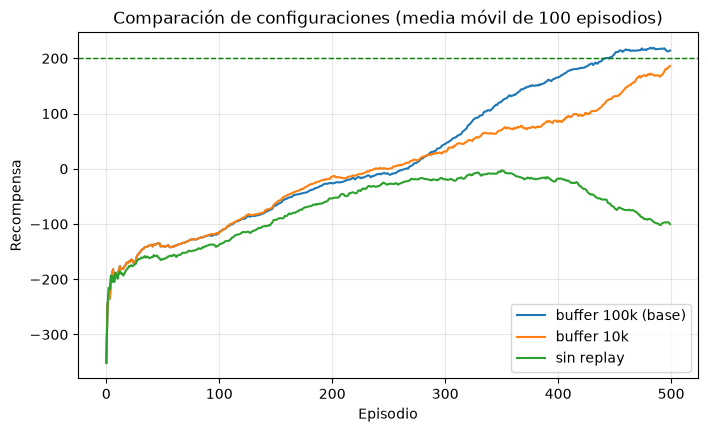

REPLAY HISTÓRICO: SALIDA ORIGINAL GUARDADA, no recálculo individual.

=== buffer 100k (base) ===
Tiempo total de entrenamiento: 89s

=== buffer 10k ===
Tiempo total de entrenamiento: 87s

=== sin replay ===
Tiempo total de entrenamiento: 97s
Configuración        |  Éxito |  R media |  Tiempo
buffer 100k (base)   |  86.0% |    247.7 |     89s
buffer 10k           |  80.0% |    223.6 |     87s
sin replay           |   0.0% |    -87.7 |     97s


In [ ]:
for h01_name,h01_h in H01['historicos'].items():
    h01_display(h01_Markdown('#### '+h01_name+' — `'+h01_h['git']+':'+h01_h['path']+'`\nSHA-256 notebook original: `'+h01_h['notebook_sha256']+'`'))
    for h01_index,h01_source in h01_h['cells'].items():
        h01_display(h01_HTML('<details><summary>Celda '+h01_index+' — SHA-256 '+h01_h['source_sha256'][h01_index]+'</summary><pre>'+h01_html.escape(h01_source)+'</pre></details>'))
h01_display(h01_HTML('<details><summary>Código original de la reevaluación auxiliar</summary><pre>'+h01_html.escape(h01_bytes(H01['policycode']).decode())+'</pre></details>'))
print('REPLAY HISTÓRICO: SALIDA ORIGINAL GUARDADA, no recálculo individual.')
for h01_output in H01['historicos']['replay']['outputs']:
    if h01_output['output_type']=='stream':
        print(''.join(h01_output['text']),end='')
    elif 'data' in h01_output:
        h01_display({k:''.join(v) if isinstance(v,list) else v for k,v in h01_output['data'].items()},raw=True)


### Reproducción histórica opcional (costosa, desactivada)
`H01_REENTRENAR=False` mantiene inertes los tres controladores. Se usan clases y funciones históricas extraídas por AST de las celdas incorporadas; nunca se asignan al espacio global del estudio. El controlador nuevo de calibración aplica los configs originales, ejecutando 300/200 episodios. Replay ejecuta la celda 24 original; exploración llama a su `correr_configuracion` original para las 15 políticas. Las nuevas salidas se devuelven por separado, sin alterar la evidencia incorporada. No se restaura un checkpoint para continuar entrenamiento ni se garantiza igualdad bit a bit entre plataformas. No se necesita Git ni acceso a resultados externos. Solo activar deliberadamente en un kernel dedicado con las dependencias instaladas.

In [ ]:
H01_REENTRENAR = False

def h01_reproducir(nombre):
    """Controlador nuevo; código histórico en namespace propio. No ejecutado por defecto."""
    if not H01_REENTRENAR:
        raise RuntimeError('Reproducción histórica desactivada: H01_REENTRENAR=False')
    import ast as h01_ast
    # No comparte las clases, RUNS ni la política final. Importaciones solo al activar.
    ns = {'__name__':'h01_historico_'+nombre}
    exec("import random, time, contextlib, io, json\nfrom abc import ABC, abstractmethod\nfrom collections import deque, namedtuple\nimport gymnasium as gym\nimport numpy as np\nimport matplotlib.pyplot as plt\nimport torch\nimport torch.nn as nn\nimport torch.nn.functional as F\nimport torch.optim as optim",ns)
    ns.update(UMBRAL_EXITO=200.0,SEMILLA=42)
    h = H01['historicos'][nombre]
    indices = {'calibracion':[11,13,15,17],'replay':[9,11,13,15],
               'exploracion':[9,11,13,15,32,34]}[nombre]
    for i in indices:
        tree = h01_ast.parse(h['cells'][str(i)])
        tree.body = [n for n in tree.body if isinstance(n,(h01_ast.FunctionDef,h01_ast.ClassDef))]
        exec(compile(tree,'historico:'+nombre+':'+str(i),'exec'),ns)
    if nombre == 'replay':
        exec(compile(h['cells']['24'],'historico:replay:24','exec'),ns)
        return ns['resultados_comparacion']
    if nombre == 'exploracion':
        exec(h['cells']['17'],ns)
        ns.update(SEMILLA_VALIDACION=50000,SEMILLA_TEST=10000,EPISODIOS_EXPERIMENTO=600,
            EPISODIOS_TEST=100,CONFIGURACIONES={'lineal':{'exploracion':'lineal'},
            'exponencial':{'exploracion':'exponencial'},'sin_exploracion':{'exploracion':'ninguna'}})
        return [ns['correr_configuracion'](n,s) for n in ns['CONFIGURACIONES'] for s in range(5)]
    resultados = []
    for item in H01['calibracion']:
        c = h01_json_file(item['config'])
        env_h = ns['gym'].make(c['environment'],continuous=c['continuous'],enable_wind=c['enable_wind'])
        try:
            import inspect as h01_inspect
            params = {k:c[k] for k in h01_inspect.signature(ns['AgenteDQN']).parameters if k in c}
            agent_h = ns['AgenteDQN'](env_h.observation_space,env_h.action_space,semilla=c['training_seed'],**params)
            train_h = ns['entrenar_agente'](agent_h,env_h,num_episodios=c['episodes'],max_pasos=c['max_steps'],umbral_resolucion=None,semilla=c['training_seed'],verbose=False)
            eval_h = ns['evaluar_agente'](agent_h,env_h,num_episodios=c['evaluation_episodes'],semilla=c['evaluation_seed'])
            resultados.append({'config':c,'training':train_h,'evaluation':eval_h})
        finally:
            env_h.close()
    return resultados

if H01_REENTRENAR:
    H01_NUEVAS_CORRIDAS = {n:h01_reproducir(n) for n in ['calibracion','replay','exploracion']}
else:
    print('Entrenamientos históricos desactivados. Solo se analizaron datos incorporados.')


Entrenamientos históricos desactivados. Solo se analizaron datos incorporados.


## Revisión de entrega
Código, 32 políticas, visualizaciones y tests integrados. Al 4/11/2026 existe informe redactado y PDF compilado de cinco páginas, idéntico en fuente de trabajo y paquete; no se repiten esos pendientes iniciales del 2/11. H01 resuelto en su alcance y H02 corregido con validación estática; H03 abierto (regla de IA no verificable). Siguen pendientes la confirmación de cualquier ampliación del nombre formal, el acuerdo metodológico del equipo, la revisión cruzada y editorial y la validación final C01 del hash vigente, incluida ejecución con kernel nuevo y revisión visual del PDF final. La evaluación reservada 30000–30199 no se ha realizado; su eventual ejecución sigue siendo una decisión pendiente. No está listo para entregar. No se entrenan políticas al ejecutar este notebook.